**Setting up Dataset**

In [ ]:
import os
from google.colab import userdata

try:
    os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
    print("Kaggle API token loaded securely.")
except Exception as error:
    print(f"Could not load Kaggle token: {error}")

Kaggle API token loaded securely.


In [ ]:
!pip install -q --upgrade kaggle

In [ ]:
!kaggle datasets list -s plantvillage

ref                                                       title                                              size  lastUpdated                 downloadCount  voteCount  usabilityRating  
--------------------------------------------------------  -------------------------------------------  ----------  --------------------------  -------------  ---------  ---------------  
abdallahalidev/plantvillage-dataset                       PlantVillage Dataset                         4371949460  2019-09-01 11:52:26.883000         120631       1045  0.875            
emmarex/plantdisease                                      PlantVillage Dataset                          689512690  2018-10-30 01:16:23.440000         172777       1230  0.5625           
mohitsingh1804/plantvillage                               PlantVillage                                  857351099  2021-08-20 01:08:58.493000          17506        104  0.625            
soumiknafiul/plantvillage-dataset-labeled                 PlantVi

In [ ]:
!mkdir -p /content/datasets

!kaggle datasets download \
  -d abdallahalidev/plantvillage-dataset \
  -p /content/datasets

Dataset URL: https://www.kaggle.com/datasets/abdallahalidev/plantvillage-dataset
License(s): CC-BY-NC-SA-4.0
plantvillage-dataset.zip: Skipping, found more recently modified local copy (use --force to force download)


In [ ]:
import os
import zipfile

DATASET_DIR = "/content/datasets/plantvillage"
ZIP_PATH = "/content/datasets/plantvillage-dataset.zip"

os.makedirs("/content/datasets", exist_ok=True)

# Download only when the ZIP and extracted dataset do not already exist
if not os.path.exists(DATASET_DIR):
    if not os.path.exists(ZIP_PATH):
        print("Downloading PlantVillage dataset...")

        exit_code = os.system(
            "kaggle datasets download "
            "-d abdallahalidev/plantvillage-dataset "
            "-p /content/datasets"
        )

        if exit_code != 0:
            raise RuntimeError("Dataset download failed.")

    print("Extracting dataset...")

    os.makedirs(DATASET_DIR, exist_ok=True)

    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(DATASET_DIR)

    print("Dataset downloaded and extracted successfully.")

else:
    print("Dataset already exists. Skipping download and extraction.")

Dataset already exists. Skipping download and extraction.


**Data Exploration**

Dataset path: /content/datasets/plantvillage/plantvillage dataset/color
Total classes found: 38
Sample classes: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy']


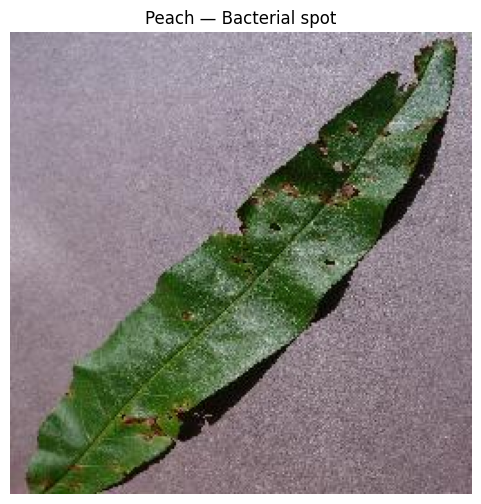

In [ ]:
import os
import random
import cv2
import matplotlib.pyplot as plt

# Automatically locate the PlantVillage "color" folder
DATASET_ROOT = "/content/datasets/plantvillage"
data_dir = None

for root, dirs, files in os.walk(DATASET_ROOT):
    if os.path.basename(root).lower() == "color":
        data_dir = root
        break

if data_dir is None:
    raise FileNotFoundError(
        "The PlantVillage color folder could not be found."
    )

print("Dataset path:", data_dir)

# Read valid class folders only
classes = sorted(
    folder
    for folder in os.listdir(data_dir)
    if os.path.isdir(os.path.join(data_dir, folder))
)

print(f"Total classes found: {len(classes)}")
print("Sample classes:", classes[:5])

# Select a random class and image
sample_class = random.choice(classes)
sample_class_path = os.path.join(data_dir, sample_class)

image_files = [
    file_name
    for file_name in os.listdir(sample_class_path)
    if file_name.lower().endswith((".jpg", ".jpeg", ".png"))
]

if not image_files:
    raise FileNotFoundError(
        f"No valid image files found in {sample_class}."
    )

sample_img_name = random.choice(image_files)
sample_img_path = os.path.join(sample_class_path, sample_img_name)

# OpenCV loads BGR, so convert it to RGB for display
img_bgr = cv2.imread(sample_img_path)

if img_bgr is None:
    raise ValueError(f"Unable to read image: {sample_img_path}")

img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6, 6))
plt.imshow(img_rgb)
plt.title(sample_class.replace("___", " — ").replace("_", " "))
plt.axis("off")
plt.show()

## Reproducibility Configuration

In [ ]:
import os
import random
import numpy as np
import tensorflow as tf

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)
os.environ["TF_DETERMINISTIC_OPS"] = "1"

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Random seed configured:", SEED)
print("TensorFlow version:", tf.__version__)

gpus = tf.config.list_physical_devices("GPU")
print("GPU available:", len(gpus) > 0)

if gpus:
    print("GPU device:", gpus[0].name)

Random seed configured: 42
TensorFlow version: 2.20.0
GPU available: True
GPU device: /physical_device:GPU:0


## Dataset Integrity and Class Distribution

In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

VALID_EXTENSIONS = {".jpg", ".jpeg", ".png"}

class_counts = {}

for class_name in classes:
    class_path = Path(data_dir) / class_name

    image_count = sum(
        1
        for file_path in class_path.iterdir()
        if file_path.is_file()
        and file_path.suffix.lower() in VALID_EXTENSIONS
    )

    class_counts[class_name] = image_count

class_distribution = (
    pd.DataFrame(
        class_counts.items(),
        columns=["class_name", "image_count"]
    )
    .sort_values("image_count", ascending=False)
    .reset_index(drop=True)
)

print("Total classes:", len(class_distribution))
print("Total images:", class_distribution["image_count"].sum())
print("Smallest class:", class_distribution.iloc[-1].to_dict())
print("Largest class:", class_distribution.iloc[0].to_dict())

display(class_distribution)

Total classes: 38
Total images: 54305
Smallest class: {'class_name': 'Potato___healthy', 'image_count': 152}
Largest class: {'class_name': 'Orange___Haunglongbing_(Citrus_greening)', 'image_count': 5507}


,class_name,image_count
0,Orange___Haunglongbing_(Citrus_greening),5507
1,Tomato___Tomato_Yellow_Leaf_Curl_Virus,5357
2,Soybean___healthy,5090
3,Peach___Bacterial_spot,2297
4,Tomato___Bacterial_spot,2127
5,Tomato___Late_blight,1909
6,Squash___Powdery_mildew,1835
7,Tomato___Septoria_leaf_spot,1771
8,Tomato___Spider_mites Two-spotted_spider_mite,1676
9,Apple___healthy,1645


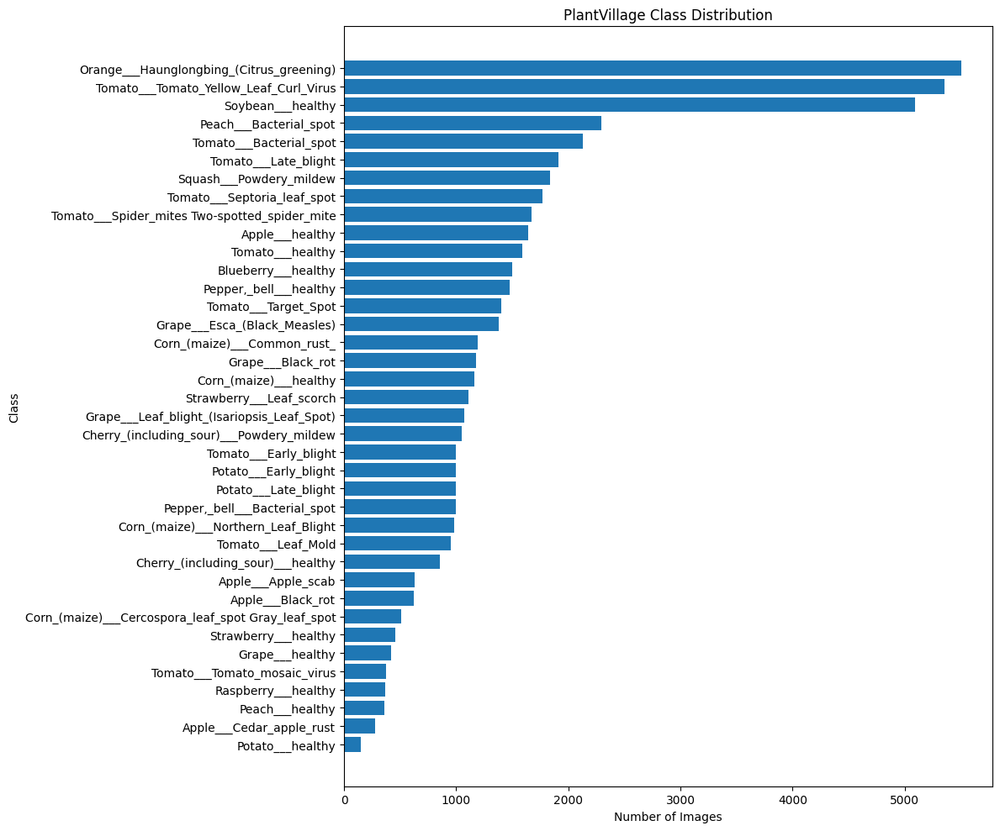

In [ ]:
plt.figure(figsize=(12, 10))

plt.barh(
    class_distribution["class_name"],
    class_distribution["image_count"]
)

plt.xlabel("Number of Images")
plt.ylabel("Class")
plt.title("PlantVillage Class Distribution")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## Stratified Train, Validation and Test Split

In [ ]:
from pathlib import Path
import pandas as pd

VALID_EXTENSIONS = {".jpg", ".jpeg", ".png"}

records = []

for class_name in classes:
    class_path = Path(data_dir) / class_name

    for image_path in class_path.iterdir():
        if (
            image_path.is_file()
            and image_path.suffix.lower() in VALID_EXTENSIONS
        ):
            records.append(
                {
                    "image_path": str(image_path),
                    "class_name": class_name,
                }
            )

dataset_df = pd.DataFrame(records)

print("Total image records:", len(dataset_df))
print("Total classes:", dataset_df["class_name"].nunique())

display(dataset_df.head())

Total image records: 54305
Total classes: 38


,image_path,class_name
0,/content/datasets/plantvillage/plantvillage da...,Apple___Apple_scab
1,/content/datasets/plantvillage/plantvillage da...,Apple___Apple_scab
2,/content/datasets/plantvillage/plantvillage da...,Apple___Apple_scab
3,/content/datasets/plantvillage/plantvillage da...,Apple___Apple_scab
4,/content/datasets/plantvillage/plantvillage da...,Apple___Apple_scab


Encoding class labels


In [ ]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

dataset_df["label"] = label_encoder.fit_transform(
    dataset_df["class_name"]
)

NUM_CLASSES = len(label_encoder.classes_)

print("Number of encoded classes:", NUM_CLASSES)

class_mapping = {
    int(index): class_name
    for index, class_name in enumerate(label_encoder.classes_)
}

print("First five mappings:")

for index in range(5):
    print(index, "->", class_mapping[index])

Number of encoded classes: 38
First five mappings:
0 -> Apple___Apple_scab
1 -> Apple___Black_rot
2 -> Apple___Cedar_apple_rust
3 -> Apple___healthy
4 -> Blueberry___healthy


In [ ]:
from sklearn.model_selection import train_test_split

# First split:
# 80% training, 20% temporary
train_df, temp_df = train_test_split(
    dataset_df,
    test_size=0.20,
    random_state=SEED,
    stratify=dataset_df["label"],
)

# Second split:
# Temporary 20% becomes 10% validation and 10% test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["label"],
)

# Reset indices
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))
print("Total:", len(train_df) + len(val_df) + len(test_df))

Training images: 43444
Validation images: 5430
Testing images: 5431
Total: 54305


In [ ]:
split_summary = pd.DataFrame(
    {
        "train": train_df["class_name"].value_counts(),
        "validation": val_df["class_name"].value_counts(),
        "test": test_df["class_name"].value_counts(),
    }
).fillna(0).astype(int)

split_summary["total"] = (
    split_summary["train"]
    + split_summary["validation"]
    + split_summary["test"]
)

split_summary = split_summary.sort_values(
    "total",
    ascending=False
)

print("Classes in training set:", train_df["class_name"].nunique())
print("Classes in validation set:", val_df["class_name"].nunique())
print("Classes in test set:", test_df["class_name"].nunique())

display(split_summary)

Classes in training set: 38
Classes in validation set: 38
Classes in test set: 38


,train,validation,test,total
class_name,,,,
Orange___Haunglongbing_(Citrus_greening),4405,551,551,5507
Tomato___Tomato_Yellow_Leaf_Curl_Virus,4286,535,536,5357
Soybean___healthy,4072,509,509,5090
Peach___Bacterial_spot,1837,230,230,2297
Tomato___Bacterial_spot,1702,212,213,2127
Tomato___Late_blight,1527,191,191,1909
Squash___Powdery_mildew,1468,183,184,1835
Tomato___Septoria_leaf_spot,1417,177,177,1771
Tomato___Spider_mites Two-spotted_spider_mite,1341,167,168,1676


In [ ]:
train_paths = set(train_df["image_path"])
val_paths = set(val_df["image_path"])
test_paths = set(test_df["image_path"])

train_val_overlap = train_paths.intersection(val_paths)
train_test_overlap = train_paths.intersection(test_paths)
val_test_overlap = val_paths.intersection(test_paths)

print("Train-validation overlap:", len(train_val_overlap))
print("Train-test overlap:", len(train_test_overlap))
print("Validation-test overlap:", len(val_test_overlap))

assert len(train_val_overlap) == 0
assert len(train_test_overlap) == 0
assert len(val_test_overlap) == 0

print("No file-path leakage detected.")

Train-validation overlap: 0
Train-test overlap: 0
Validation-test overlap: 0
No file-path leakage detected.



## TensorFlow Data Pipeline and Training-Only Augmentation

In [ ]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

Image size: (224, 224)
Batch size: 32


In [ ]:
def load_image(image_path, label):
    image_bytes = tf.io.read_file(image_path)

    image = tf.image.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        IMG_SIZE,
        method="bilinear"
    )

    image = tf.cast(image, tf.float32)

    return image, label

**Data augmentation**

In [ ]:
from tensorflow.keras import layers

data_augmentation = tf.keras.Sequential(
    [
        layers.RandomFlip(
            mode="horizontal_and_vertical",
            seed=SEED
        ),
        layers.RandomRotation(
            factor=0.08,
            fill_mode="reflect",
            seed=SEED
        ),
        layers.RandomZoom(
            height_factor=(-0.10, 0.10),
            width_factor=(-0.10, 0.10),
            fill_mode="reflect",
            seed=SEED
        ),
        layers.RandomTranslation(
            height_factor=0.08,
            width_factor=0.08,
            fill_mode="reflect",
            seed=SEED
        ),
        layers.RandomContrast(
            factor=0.10,
            seed=SEED
        ),
    ],
    name="training_augmentation"
)

**Dataset Creation Function**

In [ ]:
def create_dataset(
    dataframe,
    training=False,
    batch_size=BATCH_SIZE
):
    image_paths = dataframe["image_path"].values
    labels = dataframe["label"].values

    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(
        batch_size,
        drop_remainder=False
    )

    dataset = dataset.prefetch(AUTOTUNE)

    return dataset

**Creating train, validation and test datasets**

In [ ]:
train_ds = create_dataset(
    train_df,
    training=True
)

val_ds = create_dataset(
    val_df,
    training=False
)

test_ds = create_dataset(
    test_df,
    training=False
)

print("TensorFlow datasets created successfully.")

TensorFlow datasets created successfully.


In [ ]:
for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Image dtype:", images.dtype)
    print("Minimum pixel value:", float(tf.reduce_min(images)))
    print("Maximum pixel value:", float(tf.reduce_max(images)))

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Image dtype: <dtype: 'float32'>
Minimum pixel value: 0.0
Maximum pixel value: 255.0


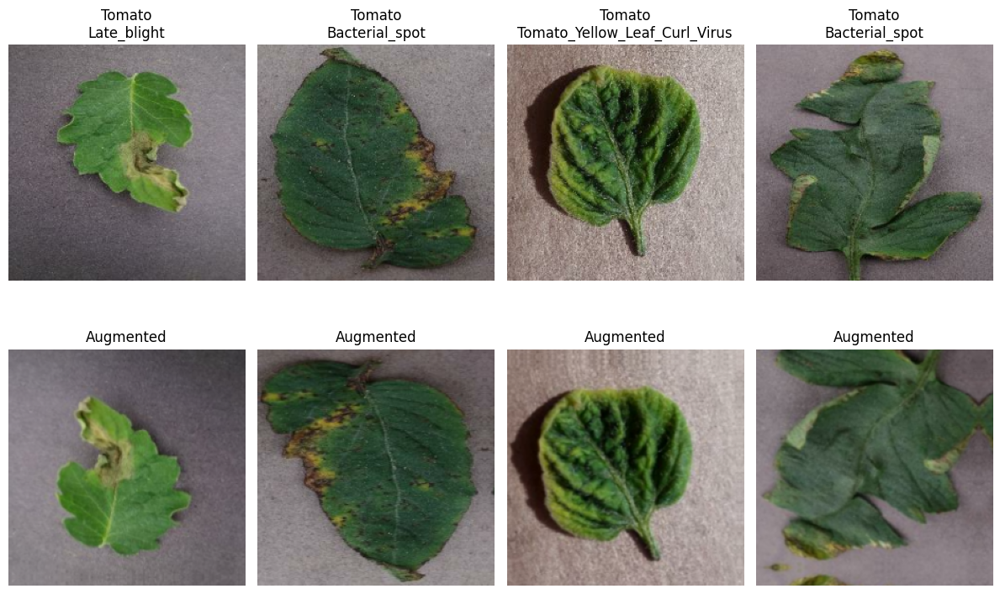

In [ ]:
import matplotlib.pyplot as plt

for images, labels in train_ds.take(1):
    sample_images = images[:4]
    sample_labels = labels[:4]

    augmented_images = data_augmentation(
        sample_images,
        training=True
    )

    plt.figure(figsize=(12, 8))

    for index in range(4):
        plt.subplot(2, 4, index + 1)
        plt.imshow(
            tf.cast(sample_images[index], tf.uint8)
        )
        plt.title(
            label_encoder.inverse_transform(
                [int(sample_labels[index])]
            )[0].replace("___", "\n")
        )
        plt.axis("off")

        plt.subplot(2, 4, index + 5)
        augmented = tf.clip_by_value(
            augmented_images[index],
            0,
            255
        )

        plt.imshow(
            tf.cast(augmented, tf.uint8)
        )
        plt.title("Augmented")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

**Class imbalance**

In [ ]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(NUM_CLASSES),
    y=train_df["label"].values
)

class_weights = {
    class_index: float(weight)
    for class_index, weight in enumerate(class_weights_array)
}

print("Class weights calculated.")
print("Smallest weight:", min(class_weights.values()))
print("Largest weight:", max(class_weights.values()))

Class weights calculated.
Smallest weight: 0.2595376067865464
Largest weight: 9.371009490940466


## MobileNetV2 Baseline Model

In [ ]:
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

inputs = layers.Input(shape=(224, 224, 3), name="input_image")

x = data_augmentation(inputs)

# Convert pixel range from [0, 255] to [-1, 1]
x = layers.Rescaling(
    scale=1.0 / 127.5,
    offset=-1,
    name="mobilenet_preprocessing"
)(x)

x = base_model(
    x,
    training=False
)

x = layers.GlobalAveragePooling2D(
    name="global_average_pooling"
)(x)

x = layers.Dropout(
    0.30,
    name="dropout"
)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    name="predictions"
)(x)

model = models.Model(
    inputs,
    outputs,
    name="CropShield_MobileNetV2_Baseline"
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "CropShield_MobileNetV2_Baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ training_augmentation           │ (None, 224, 224, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenet_preprocessing         │ (None, 224, 224, 3)    │             0 │
│ (Rescaling)                     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 38)             │        48,678 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,306,662 (8.80 MB)

 Trainable params: 48,678 (190.15 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
from tensorflow.keras.optimizers import Adam

model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.SparseTopKCategoricalAccuracy(
            k=3,
            name="top_3_accuracy"
        )
    ]
)

print("Model compiled successfully.")

Model compiled successfully.


In [ ]:
from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    ReduceLROnPlateau,
    CSVLogger
)

CHECKPOINT_PATH = "/content/cropshield_best_baseline.keras"
LOG_PATH = "/content/cropshield_baseline_training.csv"

callbacks = [
    ModelCheckpoint(
        filepath=CHECKPOINT_PATH,
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),

    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-6,
        verbose=1
    ),

    CSVLogger(
        LOG_PATH,
        append=False
    )
]

print("Callbacks configured.")

Callbacks configured.


In [ ]:
INITIAL_EPOCHS = 12

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=INITIAL_EPOCHS,
    callbacks=callbacks,
    class_weight=class_weights
)

Epoch 1/12
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - accuracy: 0.6901 - loss: 1.2774 - top_3_accuracy: 0.8373
Epoch 1: val_loss improved from None to 0.37447, saving model to /content/cropshield_best_baseline.keras

Epoch 1: finished saving model to /content/cropshield_best_baseline.keras
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 107s 71ms/step - accuracy: 0.8030 - loss: 0.7380 - top_3_accuracy: 0.9280 - val_accuracy: 0.8864 - val_loss: 0.3745 - val_top_3_accuracy: 0.9759 - learning_rate: 0.0010
Epoch 2/12
1357/1358 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - accuracy: 0.8862 - loss: 0.3820 - top_3_accuracy: 0.9747
Epoch 2: val_loss improved from 0.37447 to 0.29397, saving model to /content/cropshield_best_baseline.keras

Epoch 2: finished saving model to /content/cropshield_best_baseline.keras
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 96s 70ms/step - accuracy: 0.8893 - loss: 0.3668 - top_3_accuracy: 0.9762 - val_accuracy: 0.9068 - val_loss: 0.2940 - val_top_3_accuracy: 0.9797 - learning_rate: 0.0010
Epoch 3/12

In [ ]:
EXTRA_EPOCHS = 8

history_extra = model.fit(
    train_ds,
    validation_data=val_ds,
    initial_epoch=12,
    epochs=12 + EXTRA_EPOCHS,
    callbacks=callbacks,
    class_weight=class_weights
)

Epoch 13/20
1357/1358 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.9314 - loss: 0.2086 - top_3_accuracy: 0.9903
Epoch 13: val_loss did not improve from 0.18983
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 98s 72ms/step - accuracy: 0.9314 - loss: 0.2107 - top_3_accuracy: 0.9896 - val_accuracy: 0.9366 - val_loss: 0.1944 - val_top_3_accuracy: 0.9897 - learning_rate: 2.0000e-04
Epoch 14/20
1357/1358 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.9303 - loss: 0.2079 - top_3_accuracy: 0.9898
Epoch 14: val_loss improved from 0.18983 to 0.18031, saving model to /content/cropshield_best_baseline.keras

Epoch 14: finished saving model to /content/cropshield_best_baseline.keras
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 94s 69ms/step - accuracy: 0.9304 - loss: 0.2072 - top_3_accuracy: 0.9898 - val_accuracy: 0.9394 - val_loss: 0.1803 - val_top_3_accuracy: 0.9928 - learning_rate: 2.0000e-04
Epoch 15/20
1357/1358 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - accuracy: 0.9273 - loss: 0.2147 - top_3_accuracy: 0.9888
Epoch 15: val_lo

## Stage 2: Fine-Tuning MobileNetV2

In [ ]:
# Unfreeze the MobileNetV2 backbone
base_model.trainable = True

# Keep most layers frozen and fine-tune only the last 30 layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalization layers frozen for stable fine-tuning
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

print("Total base-model layers:", len(base_model.layers))
print(
    "Trainable base-model layers:",
    sum(layer.trainable for layer in base_model.layers)
)

Total base-model layers: 154
Trainable base-model layers: 19


In [ ]:
from tensorflow.keras.optimizers import Adam

model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.SparseTopKCategoricalAccuracy(
            k=3,
            name="top_3_accuracy"
        )
    ]
)

print("Fine-tuning model compiled.")

Fine-tuning model compiled.


In [ ]:
from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    ReduceLROnPlateau,
    CSVLogger
)

FINE_TUNE_CHECKPOINT = "/content/cropshield_best_finetuned.keras"

fine_tune_callbacks = [
    ModelCheckpoint(
        filepath=FINE_TUNE_CHECKPOINT,
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),

    EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),

    CSVLogger(
        "/content/cropshield_finetuning.csv",
        append=False
    )
]

In [ ]:
fine_tune_history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=fine_tune_callbacks,
    class_weight=class_weights
)

Epoch 1/15
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - accuracy: 0.9292 - loss: 0.2114 - top_3_accuracy: 0.9903
Epoch 1: val_loss improved from None to 0.19540, saving model to /content/cropshield_best_finetuned.keras

Epoch 1: finished saving model to /content/cropshield_best_finetuned.keras
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 119s 81ms/step - accuracy: 0.9329 - loss: 0.1994 - top_3_accuracy: 0.9915 - val_accuracy: 0.9366 - val_loss: 0.1954 - val_top_3_accuracy: 0.9867 - learning_rate: 1.0000e-05
Epoch 2/15
1357/1358 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.9434 - loss: 0.1628 - top_3_accuracy: 0.9936
Epoch 2: val_loss improved from 0.19540 to 0.15781, saving model to /content/cropshield_best_finetuned.keras

Epoch 2: finished saving model to /content/cropshield_best_finetuned.keras
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 109s 80ms/step - accuracy: 0.9443 - loss: 0.1630 - top_3_accuracy: 0.9934 - val_accuracy: 0.9492 - val_loss: 0.1578 - val_top_3_accuracy: 0.9919 - learning_rate: 1.0000e-

In [ ]:
import tensorflow as tf

baseline_model = tf.keras.models.load_model(
    "/content/cropshield_best_baseline.keras"
)

baseline_test_results = baseline_model.evaluate(
    test_ds,
    verbose=1
)

print("Baseline Test Loss:", baseline_test_results[0])
print("Baseline Test Accuracy:", baseline_test_results[1])
print("Baseline Test Top-3 Accuracy:", baseline_test_results[2])

170/170 ━━━━━━━━━━━━━━━━━━━━ 15s 64ms/step - accuracy: 0.9385 - loss: 0.1955 - top_3_accuracy: 0.9890
Baseline Test Loss: 0.19550403952598572
Baseline Test Accuracy: 0.9385011792182922
Baseline Test Top-3 Accuracy: 0.9889523386955261


In [ ]:
finetuned_model = tf.keras.models.load_model(
    "/content/cropshield_best_finetuned.keras"
)

finetuned_test_results = finetuned_model.evaluate(
    test_ds,
    verbose=1
)

print("Fine-tuned Test Loss:", finetuned_test_results[0])
print("Fine-tuned Test Accuracy:", finetuned_test_results[1])
print("Fine-tuned Test Top-3 Accuracy:", finetuned_test_results[2])

170/170 ━━━━━━━━━━━━━━━━━━━━ 13s 58ms/step - accuracy: 0.9704 - loss: 0.1002 - top_3_accuracy: 0.9971
Fine-tuned Test Loss: 0.10019274055957794
Fine-tuned Test Accuracy: 0.9703553915023804
Fine-tuned Test Top-3 Accuracy: 0.9970539212226868


In [ ]:
comparison_df = pd.DataFrame(
    {
        "Model": [
            "Frozen Baseline",
            "Fine-tuned MobileNetV2"
        ],
        "Test Loss": [
            baseline_test_results[0],
            finetuned_test_results[0]
        ],
        "Test Accuracy": [
            baseline_test_results[1],
            finetuned_test_results[1]
        ],
        "Test Top-3 Accuracy": [
            baseline_test_results[2],
            finetuned_test_results[2]
        ]
    }
)

display(comparison_df)

,Model,Test Loss,Test Accuracy,Test Top-3 Accuracy
0,Frozen Baseline,0.195504,0.938501,0.988952
1,Fine-tuned MobileNetV2,0.100193,0.970355,0.997054


In [ ]:
import numpy as np
from sklearn.metrics import classification_report

test_probabilities = finetuned_model.predict(
    test_ds,
    verbose=1
)

test_predictions = np.argmax(
    test_probabilities,
    axis=1
)

test_true_labels = test_df["label"].to_numpy()

report_dict = classification_report(
    test_true_labels,
    test_predictions,
    target_names=label_encoder.classes_,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report_dict).transpose()

display(report_df)

print("Macro Precision:", report_dict["macro avg"]["precision"])
print("Macro Recall:", report_dict["macro avg"]["recall"])
print("Macro F1:", report_dict["macro avg"]["f1-score"])
print("Weighted F1:", report_dict["weighted avg"]["f1-score"])

170/170 ━━━━━━━━━━━━━━━━━━━━ 14s 65ms/step


,precision,recall,f1-score,support
Apple___Apple_scab,1.000000,0.952381,0.975610,63.000000
Apple___Black_rot,1.000000,1.000000,1.000000,62.000000
Apple___Cedar_apple_rust,1.000000,1.000000,1.000000,27.000000
Apple___healthy,0.976190,0.993939,0.984985,165.000000
Blueberry___healthy,1.000000,0.993333,0.996656,150.000000
Cherry_(including_sour)___Powdery_mildew,1.000000,1.000000,1.000000,105.000000
Cherry_(including_sour)___healthy,0.965909,1.000000,0.982659,85.000000
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,0.888889,0.941176,0.914286,51.000000
Corn_(maize)___Common_rust_,1.000000,1.000000,1.000000,120.000000
Corn_(maize)___Northern_Leaf_Blight,0.948454,0.938776,0.943590,98.000000


Macro Precision: 0.966227502214355
Macro Recall: 0.9661953592694561
Macro F1: 0.9657168587644369
Weighted F1: 0.9704698576676906


## Confusion Matrix and Error Analysis

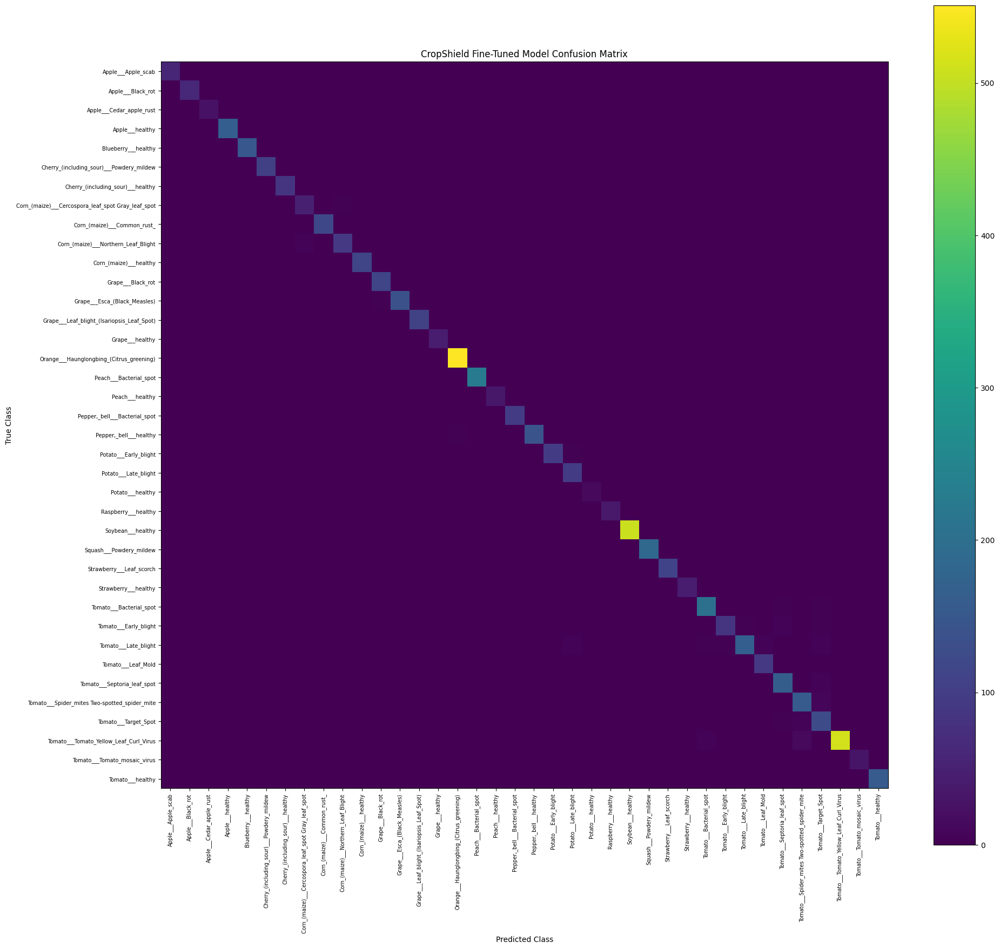

In [ ]:
from sklearn.metrics import confusion_matrix
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

conf_matrix = confusion_matrix(
    test_true_labels,
    test_predictions
)

plt.figure(figsize=(20, 18))
plt.imshow(conf_matrix, interpolation="nearest")
plt.title("CropShield Fine-Tuned Model Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.colorbar()

positions = np.arange(NUM_CLASSES)

plt.xticks(
    positions,
    label_encoder.classes_,
    rotation=90,
    fontsize=7
)

plt.yticks(
    positions,
    label_encoder.classes_,
    fontsize=7
)

plt.tight_layout()
plt.show()

In [ ]:
confusion_copy = conf_matrix.copy()
np.fill_diagonal(confusion_copy, 0)

confused_pairs = []

for true_index in range(NUM_CLASSES):
    for predicted_index in range(NUM_CLASSES):
        error_count = confusion_copy[
            true_index,
            predicted_index
        ]

        if error_count > 0:
            confused_pairs.append(
                {
                    "true_class": label_encoder.classes_[true_index],
                    "predicted_class": label_encoder.classes_[predicted_index],
                    "error_count": int(error_count)
                }
            )

confused_pairs_df = (
    pd.DataFrame(confused_pairs)
    .sort_values("error_count", ascending=False)
    .reset_index(drop=True)
)

display(confused_pairs_df.head(20))

,true_class,predicted_class,error_count
0,Tomato___Tomato_Yellow_Leaf_Curl_Virus,Tomato___Spider_mites Two-spotted_spider_mite,15
1,Tomato___Spider_mites Two-spotted_spider_mite,Tomato___Target_Spot,7
2,Corn_(maize)___Northern_Leaf_Blight,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,6
3,Tomato___Early_blight,Tomato___Septoria_leaf_spot,6
4,Tomato___Late_blight,Tomato___Target_Spot,6
5,Tomato___Late_blight,Tomato___Leaf_Mold,6
6,Tomato___Tomato_Yellow_Leaf_Curl_Virus,Tomato___Bacterial_spot,6
7,Tomato___Late_blight,Potato___Late_blight,5
8,Tomato___Target_Spot,Tomato___Spider_mites Two-spotted_spider_mite,5
9,Tomato___Septoria_leaf_spot,Tomato___Target_Spot,5


In [ ]:
incorrect_indices = np.where(
    test_predictions != test_true_labels
)[0]

print("Total incorrect predictions:", len(incorrect_indices))
print(
    "Total correct predictions:",
    len(test_predictions) - len(incorrect_indices)
)

Total incorrect predictions: 161
Total correct predictions: 5270


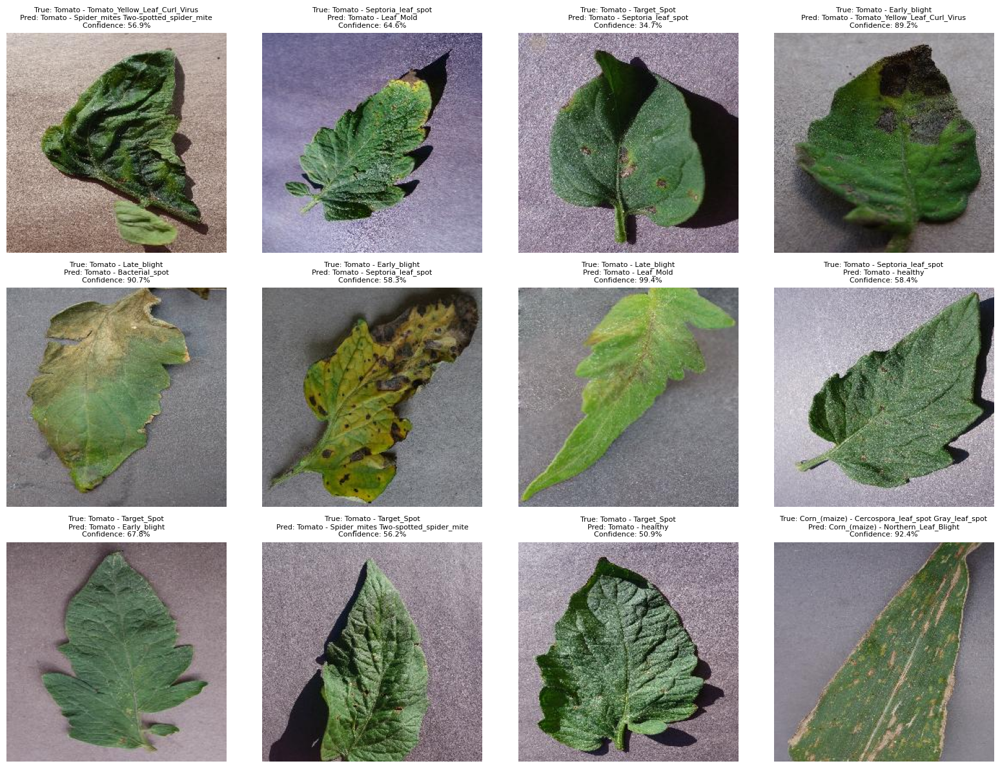

In [ ]:
import cv2
import random

sample_error_indices = random.sample(
    list(incorrect_indices),
    min(12, len(incorrect_indices))
)

plt.figure(figsize=(16, 12))

for plot_index, dataset_index in enumerate(
    sample_error_indices
):
    image_path = test_df.iloc[dataset_index]["image_path"]

    image_bgr = cv2.imread(image_path)
    image_rgb = cv2.cvtColor(
        image_bgr,
        cv2.COLOR_BGR2RGB
    )

    true_name = label_encoder.classes_[
        test_true_labels[dataset_index]
    ]

    predicted_name = label_encoder.classes_[
        test_predictions[dataset_index]
    ]

    confidence = np.max(
        test_probabilities[dataset_index]
    ) * 100

    plt.subplot(3, 4, plot_index + 1)
    plt.imshow(image_rgb)
    plt.title(
        f"True: {true_name.replace('___', ' - ')}\n"
        f"Pred: {predicted_name.replace('___', ' - ')}\n"
        f"Confidence: {confidence:.1f}%",
        fontsize=8
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

## Final Model and Metadata Export

In [ ]:
import os
import json
import pandas as pd
import tensorflow as tf

EXPORT_DIR = "/content/cropshield_export"
os.makedirs(EXPORT_DIR, exist_ok=True)

FINAL_MODEL_PATH = os.path.join(
    EXPORT_DIR,
    "cropshield_mobilenetv2_finetuned.keras"
)

finetuned_model.save(FINAL_MODEL_PATH)

print("Final model saved to:", FINAL_MODEL_PATH)

Final model saved to: /content/cropshield_export/cropshield_mobilenetv2_finetuned.keras


In [ ]:
class_mapping = {
    str(index): class_name
    for index, class_name in enumerate(
        label_encoder.classes_
    )
}

CLASS_MAPPING_PATH = os.path.join(
    EXPORT_DIR,
    "class_indices.json"
)

with open(CLASS_MAPPING_PATH, "w") as file:
    json.dump(
        class_mapping,
        file,
        indent=4
    )

print("Class mapping saved to:", CLASS_MAPPING_PATH)

Class mapping saved to: /content/cropshield_export/class_indices.json


In [ ]:
final_metrics = {
    "model_name": "CropShield MobileNetV2 Fine-tuned",
    "number_of_classes": NUM_CLASSES,
    "image_size": list(IMG_SIZE),
    "test_images": len(test_df),
    "test_loss": float(finetuned_test_results[0]),
    "test_accuracy": float(finetuned_test_results[1]),
    "test_top_3_accuracy": float(finetuned_test_results[2]),
    "macro_precision": float(
        report_dict["macro avg"]["precision"]
    ),
    "macro_recall": float(
        report_dict["macro avg"]["recall"]
    ),
    "macro_f1": float(
        report_dict["macro avg"]["f1-score"]
    ),
    "weighted_f1": float(
        report_dict["weighted avg"]["f1-score"]
    ),
    "best_fine_tuning_epoch": 13
}

METRICS_PATH = os.path.join(
    EXPORT_DIR,
    "model_metrics.json"
)

with open(METRICS_PATH, "w") as file:
    json.dump(
        final_metrics,
        file,
        indent=4
    )

print(json.dumps(final_metrics, indent=4))

{
    "model_name": "CropShield MobileNetV2 Fine-tuned",
    "number_of_classes": 38,
    "image_size": [
        224,
        224
    ],
    "test_images": 5431,
    "test_loss": 0.10019274055957794,
    "test_accuracy": 0.9703553915023804,
    "test_top_3_accuracy": 0.9970539212226868,
    "macro_precision": 0.966227502214355,
    "macro_recall": 0.9661953592694561,
    "macro_f1": 0.9657168587644369,
    "weighted_f1": 0.9704698576676906,
    "best_fine_tuning_epoch": 13
}


In [ ]:
report_df.to_csv(
    os.path.join(
        EXPORT_DIR,
        "classification_report.csv"
    )
)

confused_pairs_df.to_csv(
    os.path.join(
        EXPORT_DIR,
        "confused_class_pairs.csv"
    ),
    index=False
)

comparison_df.to_csv(
    os.path.join(
        EXPORT_DIR,
        "baseline_vs_finetuned.csv"
    ),
    index=False
)

print("Evaluation tables saved.")

Evaluation tables saved.


In [ ]:
train_df.to_csv(
    os.path.join(EXPORT_DIR, "train_split.csv"),
    index=False
)

val_df.to_csv(
    os.path.join(EXPORT_DIR, "validation_split.csv"),
    index=False
)

test_df.to_csv(
    os.path.join(EXPORT_DIR, "test_split.csv"),
    index=False
)

print("Dataset split records saved.")

Dataset split records saved.


In [ ]:
import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "/content/CropShield_Final_Artifacts",
    "zip",
    EXPORT_DIR
)

print("ZIP created:", zip_path)

files.download(zip_path)

ZIP created: /content/CropShield_Final_Artifacts.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Real-World Inference and Reliability Testing

In [ ]:
import tensorflow as tf

FINAL_MODEL_PATH = (
    "/content/cropshield_export/"
    "cropshield_mobilenetv2_finetuned.keras"
)

production_model = tf.keras.models.load_model(
    FINAL_MODEL_PATH
)

print("Production model loaded successfully.")
print("Input shape:", production_model.input_shape)
print("Output shape:", production_model.output_shape)

Production model loaded successfully.
Input shape: (None, 224, 224, 3)
Output shape: (None, 38)


In [ ]:
import numpy as np
from PIL import Image

IMAGE_SIZE = (224, 224)

def prepare_image_for_model(image):
    """
    Convert a PIL image into the exact input format expected
    by the final CropShield model.

    The model already contains MobileNetV2 normalization.
    """

    if not isinstance(image, Image.Image):
        raise TypeError("Input must be a PIL Image.")

    image = image.convert("RGB")
    image = image.resize(
        IMAGE_SIZE,
        Image.Resampling.BILINEAR
    )

    image_array = np.asarray(
        image,
        dtype=np.float32
    )

    image_batch = np.expand_dims(
        image_array,
        axis=0
    )

    return image_batch

In [ ]:
import cv2
import numpy as np

def calculate_image_quality(image):
    """
    Calculate basic blur and brightness measurements.
    """

    rgb_array = np.asarray(
        image.convert("RGB")
    )

    gray = cv2.cvtColor(
        rgb_array,
        cv2.COLOR_RGB2GRAY
    )

    blur_score = float(
        cv2.Laplacian(
            gray,
            cv2.CV_64F
        ).var()
    )

    brightness = float(
        np.mean(gray)
    )

    return {
        "blur_score": blur_score,
        "brightness": brightness,
        "is_blurry": blur_score < 60,
        "is_too_dark": brightness < 45,
        "is_too_bright": brightness > 220
    }

In [ ]:
def calculate_entropy(probabilities):
    probabilities = np.clip(
        probabilities,
        1e-10,
        1.0
    )

    entropy = -np.sum(
        probabilities * np.log(probabilities)
    )

    normalized_entropy = entropy / np.log(
        len(probabilities)
    )

    return float(normalized_entropy)

In [ ]:
def predict_crop_disease(
    image,
    model=production_model,
    class_names=label_encoder.classes_
):
    quality = calculate_image_quality(image)

    image_batch = prepare_image_for_model(image)

    probabilities = model.predict(
        image_batch,
        verbose=0
    )[0]

    sorted_indices = np.argsort(
        probabilities
    )[::-1]

    top_1_index = int(sorted_indices[0])
    top_2_index = int(sorted_indices[1])
    top_3_indices = sorted_indices[:3]

    top_1_confidence = float(
        probabilities[top_1_index]
    )

    top_2_confidence = float(
        probabilities[top_2_index]
    )

    confidence_margin = (
        top_1_confidence
        - top_2_confidence
    )

    entropy = calculate_entropy(
        probabilities
    )

    top_3 = [
        {
            "class_index": int(index),
            "class_name": class_names[index],
            "confidence": float(
                probabilities[index]
            )
        }
        for index in top_3_indices
    ]

    return {
        "predicted_class": class_names[top_1_index],
        "confidence": top_1_confidence,
        "confidence_margin": confidence_margin,
        "entropy": entropy,
        "top_3": top_3,
        "quality": quality
    }

In [ ]:
def determine_prediction_status(result):
    quality = result["quality"]

    if quality["is_blurry"]:
        return {
            "status": "unclear_image",
            "message": (
                "The image appears blurry. "
                "Capture a sharper photo."
            )
        }

    if quality["is_too_dark"]:
        return {
            "status": "unclear_image",
            "message": (
                "The image is too dark. "
                "Use better lighting."
            )
        }

    if quality["is_too_bright"]:
        return {
            "status": "unclear_image",
            "message": (
                "The image is overexposed. "
                "Avoid direct harsh light."
            )
        }

    confidence = result["confidence"]
    margin = result["confidence_margin"]
    entropy = result["entropy"]

    if (
        confidence < 0.65
        or margin < 0.15
        or entropy > 0.45
    ):
        return {
            "status": "uncertain",
            "message": (
                "The diagnosis is uncertain. "
                "Retake the image or consult an expert."
            )
        }

    return {
        "status": "confident",
        "message": (
            "The model produced a sufficiently "
            "confident prediction."
        )
    }

In [ ]:
from google.colab import files

uploaded_images = files.upload()

Saving WhatsApp Image 2026-08-02 at 3.50.03 PM (1).jpeg to WhatsApp Image 2026-08-02 at 3.50.03 PM (1).jpeg
Saving WhatsApp Image 2026-08-02 at 3.50.03 PM.jpeg to WhatsApp Image 2026-08-02 at 3.50.03 PM.jpeg
Saving WhatsApp Image 2026-08-02 at 3.50.02 PM.jpeg to WhatsApp Image 2026-08-02 at 3.50.02 PM.jpeg
Saving WhatsApp Image 2026-08-02 at 3.50.01 PM (2).jpeg to WhatsApp Image 2026-08-02 at 3.50.01 PM (2).jpeg
Saving WhatsApp Image 2026-08-02 at 3.50.01 PM (1).jpeg to WhatsApp Image 2026-08-02 at 3.50.01 PM (1).jpeg
Saving WhatsApp Image 2026-08-02 at 3.50.01 PM.jpeg to WhatsApp Image 2026-08-02 at 3.50.01 PM.jpeg
Saving WhatsApp Image 2026-08-02 at 3.50.00 PM.jpeg to WhatsApp Image 2026-08-02 at 3.50.00 PM.jpeg


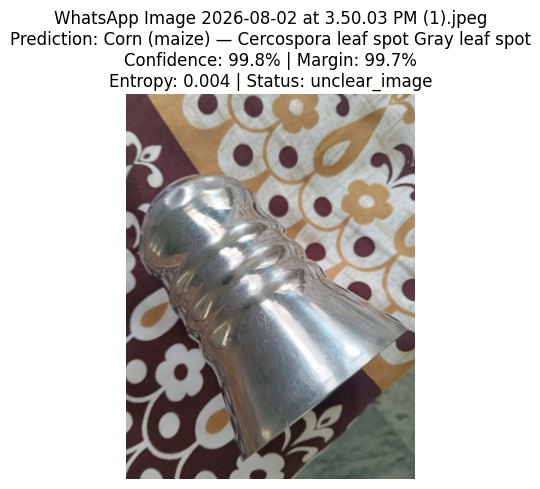

Top 3 predictions:
- Corn (maize) — Cercospora leaf spot Gray leaf spot: 99.81%
- Corn (maize) — healthy: 0.15%
- Tomato — Early blight: 0.01%
Quality: {'blur_score': 25.65393218939997, 'brightness': 127.34984635416667, 'is_blurry': True, 'is_too_dark': False, 'is_too_bright': False}
Decision: The image appears blurry. Capture a sharper photo.
--------------------------------------------------------------------------------


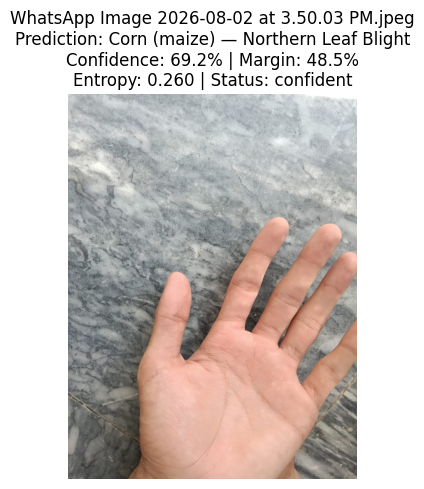

Top 3 predictions:
- Corn (maize) — Northern Leaf Blight: 69.15%
- Tomato — Late blight: 20.64%
- Corn (maize) — Common rust : 5.05%
Quality: {'blur_score': 238.09884843642337, 'brightness': 162.9965859375, 'is_blurry': False, 'is_too_dark': False, 'is_too_bright': False}
Decision: The model produced a sufficiently confident prediction.
--------------------------------------------------------------------------------


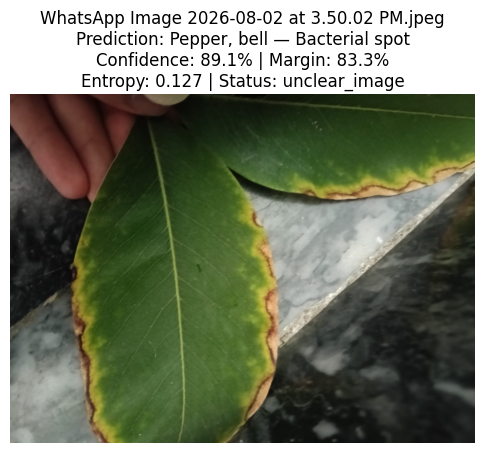

Top 3 predictions:
- Pepper, bell — Bacterial spot: 89.09%
- Blueberry — healthy: 5.79%
- Cherry (including sour) — Powdery mildew: 4.05%
Quality: {'blur_score': 8.896019209628633, 'brightness': 77.7447078125, 'is_blurry': True, 'is_too_dark': False, 'is_too_bright': False}
Decision: The image appears blurry. Capture a sharper photo.
--------------------------------------------------------------------------------


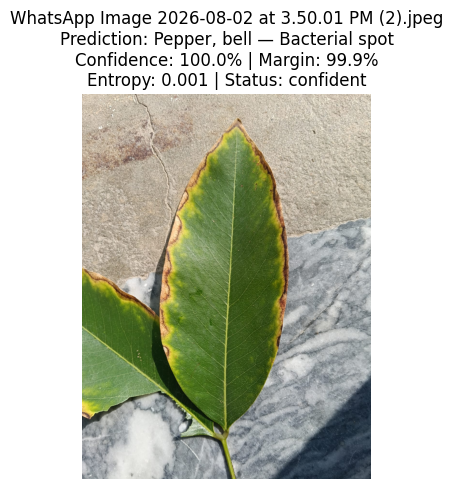

Top 3 predictions:
- Pepper, bell — Bacterial spot: 99.97%
- Orange — Haunglongbing (Citrus greening): 0.03%
- Tomato — Early blight: 0.00%
Quality: {'blur_score': 848.6240299716915, 'brightness': 144.88142083333332, 'is_blurry': False, 'is_too_dark': False, 'is_too_bright': False}
Decision: The model produced a sufficiently confident prediction.
--------------------------------------------------------------------------------


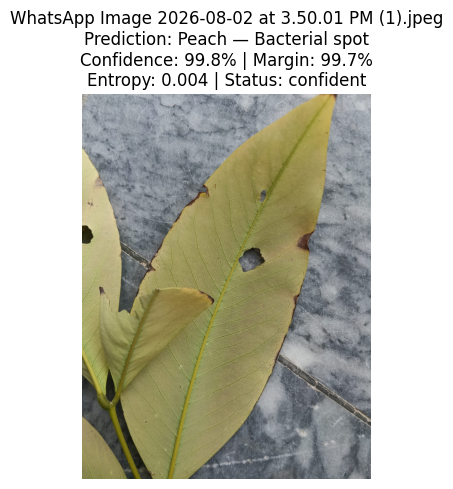

Top 3 predictions:
- Peach — Bacterial spot: 99.82%
- Pepper, bell — Bacterial spot: 0.16%
- Soybean — healthy: 0.02%
Quality: {'blur_score': 795.6018739538886, 'brightness': 135.0109703125, 'is_blurry': False, 'is_too_dark': False, 'is_too_bright': False}
Decision: The model produced a sufficiently confident prediction.
--------------------------------------------------------------------------------


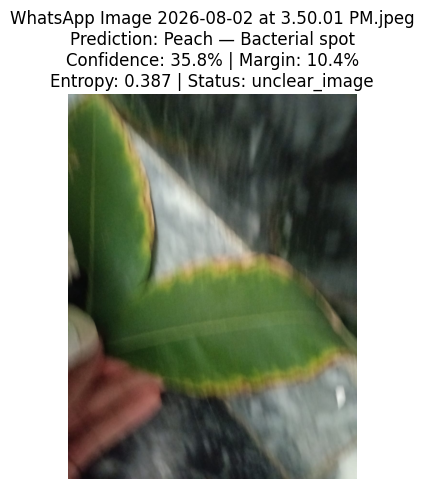

Top 3 predictions:
- Peach — Bacterial spot: 35.80%
- Corn (maize) — Northern Leaf Blight: 25.36%
- Cherry (including sour) — Powdery mildew: 22.41%
Quality: {'blur_score': 6.927449479068744, 'brightness': 85.98982604166666, 'is_blurry': True, 'is_too_dark': False, 'is_too_bright': False}
Decision: The image appears blurry. Capture a sharper photo.
--------------------------------------------------------------------------------


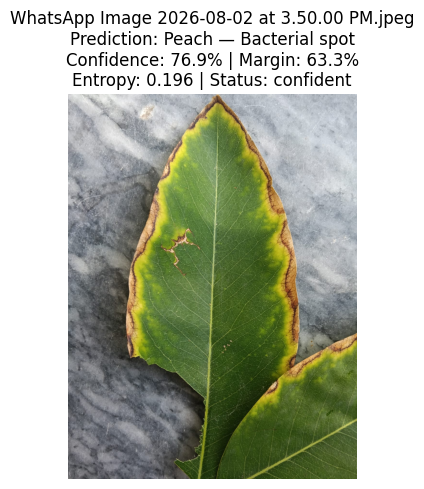

Top 3 predictions:
- Peach — Bacterial spot: 76.87%
- Pepper, bell — Bacterial spot: 13.54%
- Tomato — Bacterial spot: 9.36%
Quality: {'blur_score': 480.0642541315102, 'brightness': 123.58605, 'is_blurry': False, 'is_too_dark': False, 'is_too_bright': False}
Decision: The model produced a sufficiently confident prediction.
--------------------------------------------------------------------------------


In [ ]:
import io
import matplotlib.pyplot as plt

real_world_results = []

for file_name, file_data in uploaded_images.items():
    image = Image.open(
        io.BytesIO(file_data)
    ).convert("RGB")

    result = predict_crop_disease(
        image
    )

    decision = determine_prediction_status(
        result
    )

    real_world_results.append(
        {
            "file_name": file_name,
            **result,
            **decision
        }
    )

    display_name = result[
        "predicted_class"
    ].replace("___", " — ").replace("_", " ")

    plt.figure(figsize=(6, 5))
    plt.imshow(image)
    plt.axis("off")

    plt.title(
        f"{file_name}\n"
        f"Prediction: {display_name}\n"
        f"Confidence: "
        f"{result['confidence'] * 100:.1f}% | "
        f"Margin: "
        f"{result['confidence_margin'] * 100:.1f}%\n"
        f"Entropy: {result['entropy']:.3f} | "
        f"Status: {decision['status']}"
    )

    plt.show()

    print("Top 3 predictions:")

    for prediction in result["top_3"]:
        clean_name = prediction[
            "class_name"
        ].replace("___", " — ").replace("_", " ")

        print(
            f"- {clean_name}: "
            f"{prediction['confidence'] * 100:.2f}%"
        )

    print("Quality:", result["quality"])
    print("Decision:", decision["message"])
    print("-" * 80)

## Lightweight Leaf Validator Dataset

In [ ]:
import tensorflow as tf

SEED = 42

LEAF_VALIDATOR_TRAIN_PER_CLASS = 6000
LEAF_VALIDATOR_VAL_PER_CLASS = 750
LEAF_VALIDATOR_TEST_PER_CLASS = 750

LEAF_IMG_SIZE = (128, 128)
LEAF_BATCH_SIZE = 16

NOT_LEAF_LABEL = 0
LEAF_LABEL = 1

print("Memory-safe leaf validator configuration loaded.")

Memory-safe leaf validator configuration loaded.


In [ ]:
leaf_train_df = (
    train_df
    .sample(
        n=LEAF_VALIDATOR_TRAIN_PER_CLASS,
        random_state=SEED
    )
    .reset_index(drop=True)
)

leaf_val_df = (
    val_df
    .sample(
        n=LEAF_VALIDATOR_VAL_PER_CLASS,
        random_state=SEED
    )
    .reset_index(drop=True)
)

leaf_test_df = (
    test_df
    .sample(
        n=LEAF_VALIDATOR_TEST_PER_CLASS,
        random_state=SEED
    )
    .reset_index(drop=True)
)

print("Leaf train:", len(leaf_train_df))
print("Leaf validation:", len(leaf_val_df))
print("Leaf test:", len(leaf_test_df))

Leaf train: 6000
Leaf validation: 750
Leaf test: 750


In [ ]:
def load_leaf_positive(image_path):
    image_bytes = tf.io.read_file(image_path)

    image = tf.image.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        LEAF_IMG_SIZE,
        method="bilinear"
    )

    image = tf.cast(image, tf.float32)

    return image, tf.constant(
        LEAF_LABEL,
        dtype=tf.float32
    )

In [ ]:
leaf_train_ds = (
    tf.data.Dataset
    .from_tensor_slices(
        leaf_train_df["image_path"].values
    )
    .map(
        load_leaf_positive,
        num_parallel_calls=2
    )
)

leaf_val_ds = (
    tf.data.Dataset
    .from_tensor_slices(
        leaf_val_df["image_path"].values
    )
    .map(
        load_leaf_positive,
        num_parallel_calls=2
    )
)

leaf_test_ds = (
    tf.data.Dataset
    .from_tensor_slices(
        leaf_test_df["image_path"].values
    )
    .map(
        load_leaf_positive,
        num_parallel_calls=2
    )
)

print("Leaf-positive datasets created.")

Leaf-positive datasets created.


In [ ]:
import gc
import numpy as np
import tensorflow as tf
from tensorflow.keras.datasets import cifar10

# CIFAR-10 load karo
(x_cifar_train, _), (x_cifar_test, _) = cifar10.load_data()

# Sirf jitni images chahiye utni rakho
x_cifar_train_small = x_cifar_train[
    :LEAF_VALIDATOR_TRAIN_PER_CLASS
    + LEAF_VALIDATOR_VAL_PER_CLASS
].copy()

x_cifar_test_small = x_cifar_test[
    :LEAF_VALIDATOR_TEST_PER_CLASS
].copy()

# Full arrays memory se remove karo
del x_cifar_train
del x_cifar_test

gc.collect()

print("Reduced CIFAR train shape:", x_cifar_train_small.shape)
print("Reduced CIFAR test shape:", x_cifar_test_small.shape)
print(
    "Pixel range:",
    x_cifar_train_small.min(),
    "to",
    x_cifar_train_small.max()
)

Reduced CIFAR train shape: (6750, 32, 32, 3)
Reduced CIFAR test shape: (750, 32, 32, 3)
Pixel range: 0 to 255


In [ ]:
def prepare_non_leaf(image):
    image = tf.image.resize(
        image,
        LEAF_IMG_SIZE,
        method="bilinear"
    )

    image = tf.cast(image, tf.float32)

    return image, tf.constant(
        NOT_LEAF_LABEL,
        dtype=tf.float32
    )

In [ ]:
non_leaf_train_ds = tf.data.Dataset.from_tensor_slices(
    x_cifar_train_small[
        :LEAF_VALIDATOR_TRAIN_PER_CLASS
    ]
).map(
    prepare_non_leaf,
    num_parallel_calls=2
)

val_start = LEAF_VALIDATOR_TRAIN_PER_CLASS
val_end = val_start + LEAF_VALIDATOR_VAL_PER_CLASS

non_leaf_val_ds = tf.data.Dataset.from_tensor_slices(
    x_cifar_train_small[val_start:val_end]
).map(
    prepare_non_leaf,
    num_parallel_calls=2
)

non_leaf_test_ds = tf.data.Dataset.from_tensor_slices(
    x_cifar_test_small[
        :LEAF_VALIDATOR_TEST_PER_CLASS
    ]
).map(
    prepare_non_leaf,
    num_parallel_calls=2
)

print("Non-leaf datasets created.")

Non-leaf datasets created.


In [ ]:
val_start = LEAF_VALIDATOR_TRAIN_PER_CLASS
val_end = val_start + LEAF_VALIDATOR_VAL_PER_CLASS

non_leaf_val_ds = tf.data.Dataset.from_tensor_slices(
    x_cifar_train_small[val_start:val_end]
).map(
    prepare_non_leaf,
    num_parallel_calls=2
)

non_leaf_test_ds = tf.data.Dataset.from_tensor_slices(
    x_cifar_test_small[
        :LEAF_VALIDATOR_TEST_PER_CLASS
    ]
).map(
    prepare_non_leaf,
    num_parallel_calls=2
)

print("Non-leaf validation and test datasets created.")

Non-leaf validation and test datasets created.


In [ ]:
leaf_validator_train_ds = (
    leaf_train_ds
    .concatenate(non_leaf_train_ds)
    .shuffle(
        buffer_size=2000,
        seed=SEED,
        reshuffle_each_iteration=True
    )
    .batch(
        LEAF_BATCH_SIZE,
        drop_remainder=False
    )
    .prefetch(1)
)

leaf_validator_val_ds = (
    leaf_val_ds
    .concatenate(non_leaf_val_ds)
    .batch(
        LEAF_BATCH_SIZE,
        drop_remainder=False
    )
    .prefetch(1)
)

leaf_validator_test_ds = (
    leaf_test_ds
    .concatenate(non_leaf_test_ds)
    .batch(
        LEAF_BATCH_SIZE,
        drop_remainder=False
    )
    .prefetch(1)
)

print("Memory-safe leaf-validator datasets created.")

Memory-safe leaf-validator datasets created.


**Batch verification**

In [ ]:
for images, labels in leaf_validator_train_ds.take(1):
    print("Image shape:", images.shape)
    print("Label shape:", labels.shape)
    print("Pixel minimum:", float(tf.reduce_min(images)))
    print("Pixel maximum:", float(tf.reduce_max(images)))

    unique_labels, _, counts = tf.unique_with_counts(
        tf.cast(labels, tf.int32)
    )

    print(
        "Labels in batch:",
        dict(
            zip(
                unique_labels.numpy().tolist(),
                counts.numpy().tolist()
            )
        )
    )

Image shape: (16, 128, 128, 3)
Label shape: (16,)
Pixel minimum: 0.0
Pixel maximum: 237.0
Labels in batch: {1: 16}


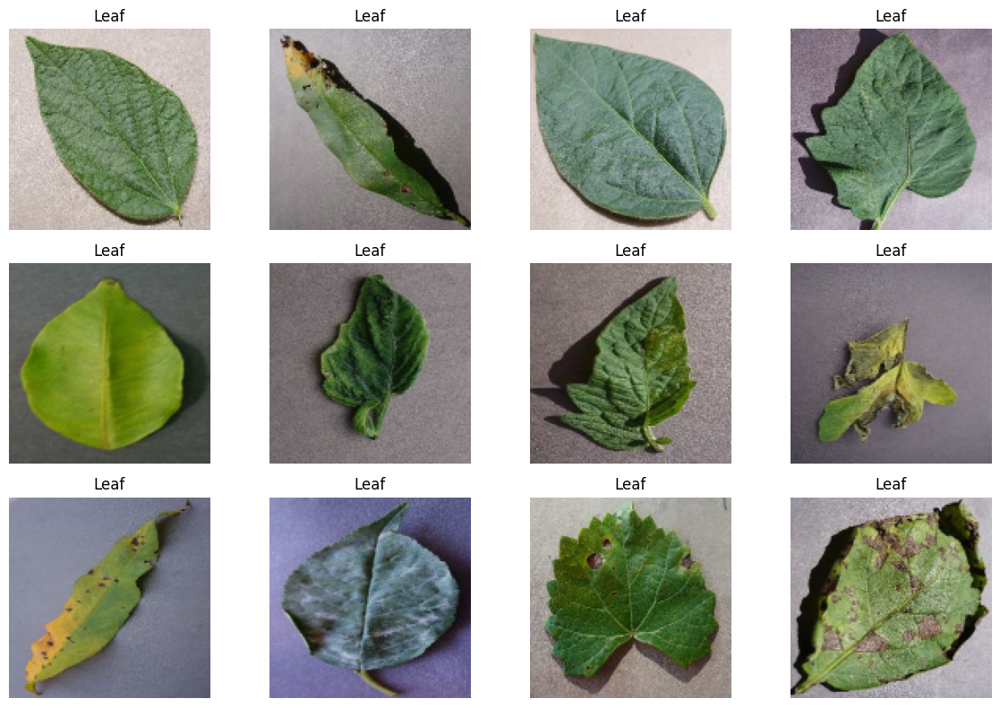

In [ ]:
import matplotlib.pyplot as plt

for images, labels in leaf_validator_train_ds.take(1):
    plt.figure(figsize=(12, 8))

    for index in range(12):
        plt.subplot(3, 4, index + 1)
        plt.imshow(tf.cast(images[index], tf.uint8))

        label_name = (
            "Leaf"
            if int(labels[index].numpy()) == 1
            else "Not Leaf"
        )

        plt.title(label_name)
        plt.axis("off")

    plt.tight_layout()
    plt.show()

In [ ]:
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV3Small

leaf_augmentation = tf.keras.Sequential(
    [
        layers.RandomFlip("horizontal_and_vertical", seed=SEED),
        layers.RandomRotation(0.08, seed=SEED),
        layers.RandomZoom(0.10, seed=SEED),
        layers.RandomContrast(0.10, seed=SEED),
    ],
    name="leaf_augmentation"
)

leaf_base_model = MobileNetV3Small(
    weights="imagenet",
    include_top=False,
    input_shape=(160, 160, 3),
    include_preprocessing=True
)

leaf_base_model.trainable = False

inputs = layers.Input(
    shape=(160, 160, 3),
    name="input_image"
)

x = leaf_augmentation(inputs)

x = leaf_base_model(
    x,
    training=False
)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.25)(x)

outputs = layers.Dense(
    1,
    activation="sigmoid",
    name="leaf_probability"
)(x)

leaf_validator_model = models.Model(
    inputs,
    outputs,
    name="CropShield_Leaf_Validator"
)

leaf_validator_model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/applications/mobilenet_v3.py:454: UserWarning: `input_shape` is undefined or non-square, or `rows` is not 224. Weights for input shape (224, 224) will be loaded as the default.
  return MobileNetV3(


Model: "CropShield_Leaf_Validator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaf_augmentation (Sequential)  │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MobileNetV3Small (Functional)   │ (None, 5, 5, 576)      │       939,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 576)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaf_probability (Dense)        │ (None, 1)              │           577 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 939,697 (3.58 MB)

 Trainable params: 577 (2.25 KB)

 Non-trainable params: 939,120 (3.58 MB)

In [ ]:
leaf_validator_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

print("Leaf validator compiled.")

Leaf validator compiled.


In [ ]:
import gc
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV3Small

tf.keras.backend.clear_session()
gc.collect()

leaf_augmentation = tf.keras.Sequential(
    [
        layers.RandomFlip(
            "horizontal_and_vertical",
            seed=SEED
        ),
        layers.RandomRotation(
            0.05,
            seed=SEED
        ),
        layers.RandomZoom(
            0.08,
            seed=SEED
        ),
    ],
    name="leaf_augmentation"
)

leaf_base_model = MobileNetV3Small(
    weights="imagenet",
    include_top=False,
    input_shape=(128, 128, 3),
    include_preprocessing=True,
    minimalistic=True
)

leaf_base_model.trainable = False

inputs = layers.Input(
    shape=(128, 128, 3),
    name="input_image"
)

x = leaf_augmentation(inputs)
x = leaf_base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.20)(x)

outputs = layers.Dense(
    1,
    activation="sigmoid",
    name="leaf_probability"
)(x)

leaf_validator_model = models.Model(
    inputs,
    outputs,
    name="CropShield_Leaf_Validator"
)

print("Model input shape:", leaf_validator_model.input_shape)

2128592/2128592 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Model input shape: (None, 128, 128, 3)


In [ ]:
leaf_validator_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

print("Leaf validator compiled.")

Leaf validator compiled.


In [ ]:
leaf_history = leaf_validator_model.fit(
    leaf_validator_train_ds,
    validation_data=leaf_validator_val_ds,
    epochs=8,
    callbacks=leaf_validator_callbacks
)

Epoch 1/8
750/750 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9945 - auc: 0.6407 - loss: 0.0301 - precision: 0.9941 - recall: 0.9983
Epoch 1: val_loss improved from None to 0.01315, saving model to /content/cropshield_best_leaf_validator.keras

Epoch 1: finished saving model to /content/cropshield_best_leaf_validator.keras
750/750 ━━━━━━━━━━━━━━━━━━━━ 27s 21ms/step - accuracy: 0.9937 - auc: 0.9985 - loss: 0.0297 - precision: 0.9909 - recall: 0.9965 - val_accuracy: 0.9947 - val_auc: 1.0000 - val_loss: 0.0132 - val_precision: 1.0000 - val_recall: 0.9893 - learning_rate: 0.0010
Epoch 2/8
747/750 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9965 - auc: 0.6586 - loss: 0.0115 - precision: 0.9995 - recall: 0.9965
Epoch 2: val_loss improved from 0.01315 to 0.00404, saving model to /content/cropshield_best_leaf_validator.keras

Epoch 2: finished saving model to /content/cropshield_best_leaf_validator.keras
750/750 ━━━━━━━━━━━━━━━━━━━━ 13s 16ms/step - accuracy: 0.9984 - auc: 1.0000 - loss

In [ ]:
leaf_validator_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "/content/cropshield_best_leaf_validator.keras",
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

In [ ]:
leaf_validator_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "/content/cropshield_best_leaf_validator.keras",
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

In [ ]:
leaf_history = leaf_validator_model.fit(
    leaf_validator_train_ds,
    validation_data=leaf_validator_val_ds,
    epochs=12,
    callbacks=leaf_validator_callbacks
)

Epoch 1/12
747/750 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9986 - auc: 0.6626 - loss: 0.0031 - precision: 0.9997 - recall: 0.9986
Epoch 1: val_loss improved from None to 0.00032, saving model to /content/cropshield_best_leaf_validator.keras

Epoch 1: finished saving model to /content/cropshield_best_leaf_validator.keras
750/750 ━━━━━━━━━━━━━━━━━━━━ 14s 17ms/step - accuracy: 0.9990 - auc: 1.0000 - loss: 0.0023 - precision: 0.9992 - recall: 0.9988 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 3.1786e-04 - val_precision: 1.0000 - val_recall: 1.0000 - learning_rate: 2.0000e-04
Epoch 2/12
745/750 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9994 - auc: 0.6617 - loss: 0.0024 - precision: 0.9999 - recall: 0.9994
Epoch 2: val_loss improved from 0.00032 to 0.00029, saving model to /content/cropshield_best_leaf_validator.keras

Epoch 2: finished saving model to /content/cropshield_best_leaf_validator.keras
750/750 ━━━━━━━━━━━━━━━━━━━━ 20s 16ms/step - accuracy: 0.9997 - auc: 0.9

In [ ]:
leaf_test_results = leaf_validator_model.evaluate(
    leaf_validator_test_ds,
    verbose=1
)

print("Test Loss:", leaf_test_results[0])
print("Test Accuracy:", leaf_test_results[1])
print("Test Precision:", leaf_test_results[2])
print("Test Recall:", leaf_test_results[3])
print("Test AUC:", leaf_test_results[4])

94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 1.7970e-04 - precision: 1.0000 - recall: 1.0000
Test Loss: 0.0001796990109141916
Test Accuracy: 1.0
Test Precision: 1.0
Test Recall: 1.0
Test AUC: 1.0


In [ ]:
import numpy as np
from PIL import Image

def prepare_for_leaf_validator(image):
    image = image.convert("RGB")
    image = image.resize(
        LEAF_IMG_SIZE,
        Image.Resampling.BILINEAR
    )

    image_array = np.asarray(
        image,
        dtype=np.float32
    )

    return np.expand_dims(image_array, axis=0)


def predict_leaf_probability(image):
    image_batch = prepare_for_leaf_validator(image)

    probability = float(
        leaf_validator_model.predict(
            image_batch,
            verbose=0
        )[0][0]
    )

    return {
        "leaf_probability": probability,
        "prediction": (
            "Leaf"
            if probability >= 0.5
            else "Not Leaf"
        )
    }

In [ ]:
from google.colab import files

validator_test_uploads = files.upload()

Saving WhatsApp Image 2026-08-02 at 3.50.03 PM (1).jpeg to WhatsApp Image 2026-08-02 at 3.50.03 PM (1) (1).jpeg
Saving WhatsApp Image 2026-08-02 at 3.50.03 PM.jpeg to WhatsApp Image 2026-08-02 at 3.50.03 PM (2).jpeg
Saving WhatsApp Image 2026-08-02 at 3.50.02 PM.jpeg to WhatsApp Image 2026-08-02 at 3.50.02 PM (1).jpeg
Saving WhatsApp Image 2026-08-02 at 3.50.01 PM (2).jpeg to WhatsApp Image 2026-08-02 at 3.50.01 PM (2) (1).jpeg
Saving WhatsApp Image 2026-08-02 at 3.50.01 PM (1).jpeg to WhatsApp Image 2026-08-02 at 3.50.01 PM (1) (1).jpeg
Saving WhatsApp Image 2026-08-02 at 3.50.01 PM.jpeg to WhatsApp Image 2026-08-02 at 3.50.01 PM (3).jpeg
Saving WhatsApp Image 2026-08-02 at 3.50.00 PM.jpeg to WhatsApp Image 2026-08-02 at 3.50.00 PM (1).jpeg


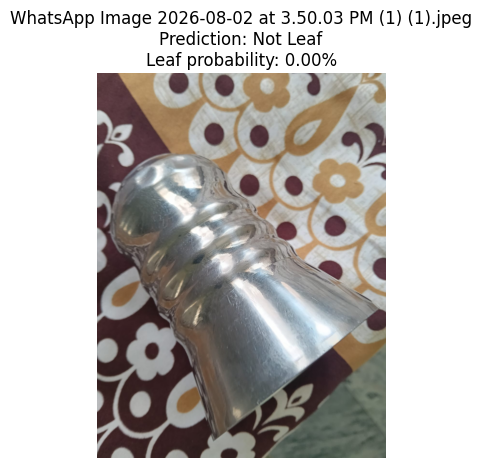

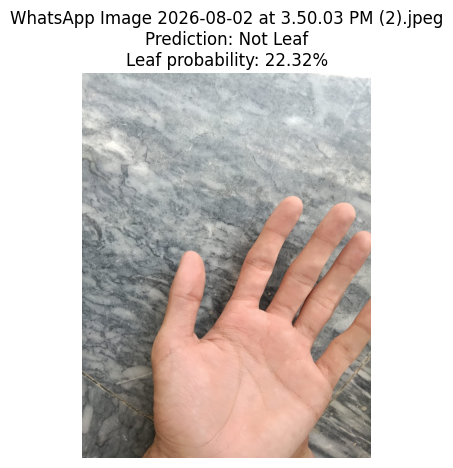

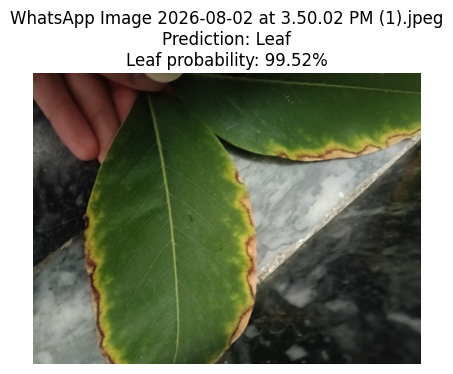

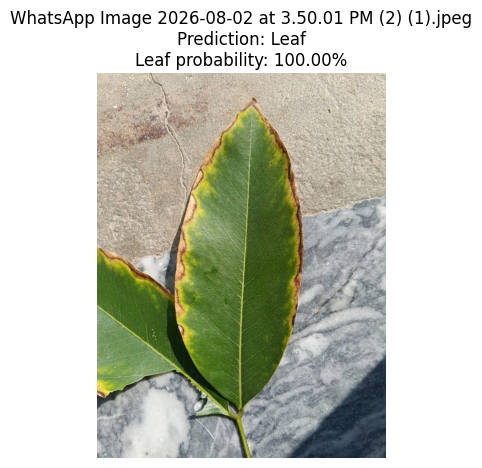

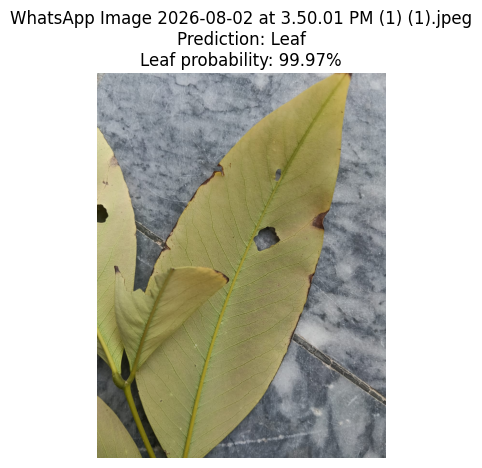

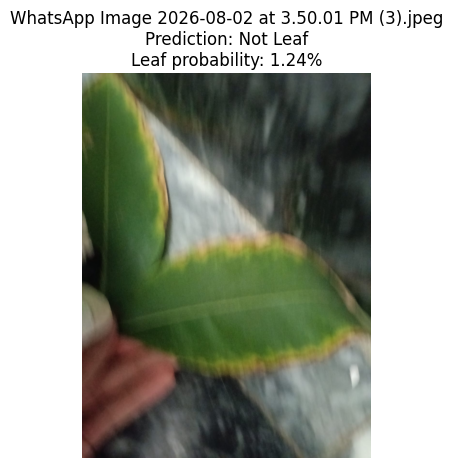

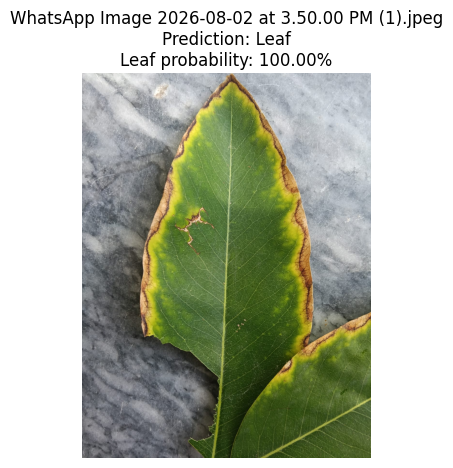

In [ ]:
import io
import matplotlib.pyplot as plt

for file_name, file_data in validator_test_uploads.items():
    image = Image.open(
        io.BytesIO(file_data)
    ).convert("RGB")

    result = predict_leaf_probability(image)

    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    plt.axis("off")
    plt.title(
        f"{file_name}\n"
        f"Prediction: {result['prediction']}\n"
        f"Leaf probability: "
        f"{result['leaf_probability'] * 100:.2f}%"
    )
    plt.show()

In [ ]:
LEAF_THRESHOLD = 0.80
UNCERTAIN_THRESHOLD = 0.30

def classify_leaf_suitability(image):
    image_batch = prepare_for_leaf_validator(image)

    leaf_probability = float(
        leaf_validator_model.predict(
            image_batch,
            verbose=0
        )[0][0]
    )

    if leaf_probability >= LEAF_THRESHOLD:
        status = "suitable_leaf"
        message = "A suitable leaf image was detected."

    elif leaf_probability >= UNCERTAIN_THRESHOLD:
        status = "uncertain"
        message = (
            "The image may contain a leaf, but it is unclear. "
            "Capture a sharper, closer photo."
        )

    else:
        status = "not_leaf"
        message = (
            "No suitable plant leaf was detected. "
            "Upload a clear leaf image."
        )

    return {
        "leaf_probability": leaf_probability,
        "status": status,
        "message": message
    }

In [ ]:
LEAF_VALIDATOR_PATH = (
    "/content/cropshield_export/"
    "cropshield_leaf_validator.keras"
)

leaf_validator_model.save(
    LEAF_VALIDATOR_PATH
)

print("Leaf validator saved:", LEAF_VALIDATOR_PATH)

Leaf validator saved: /content/cropshield_export/cropshield_leaf_validator.keras


In [ ]:
import json
import os

validator_metadata = {
    "model_name": "CropShield Leaf Suitability Validator",
    "input_size": [128, 128],
    "output": "leaf_probability",
    "suitable_leaf_threshold": 0.80,
    "uncertain_threshold": 0.30,
    "test_accuracy_on_internal_dataset": 1.0,
    "known_limitation": (
        "Internal evaluation uses PlantVillage leaves and "
        "CIFAR-10 negatives; broader real-world validation is required."
    )
}

with open(
    "/content/cropshield_export/leaf_validator_metadata.json",
    "w"
) as file:
    json.dump(
        validator_metadata,
        file,
        indent=4
    )

print("Validator metadata saved.")

Validator metadata saved.


## Optional Academic Experiment: Traditional Feature Extraction and ML Classifiers

This section compares manually engineered image descriptors with deep learning.
It is retained for academic reference and is not used in the final CropShield
production pipeline.

**Extracting features through Descripters(HOG,SIFT....)**

In [ ]:
import numpy as np
import pandas as pd
from skimage.feature import hog, graycomatrix, graycoprops
from tqdm import tqdm
import cv2
import os

LIMIT_PER_CLASS = 50
features_list = []
labels_list = []

# Initialize SIFT (Local Descriptor)
sift = cv2.SIFT_create()

print("Running Full Feature Extraction (HOG, GLCM, GLRM, SIFT)...")

for label in tqdm(classes):
    class_path = os.path.join(data_dir, label)
    images = os.listdir(class_path)[:LIMIT_PER_CLASS]

    for img_name in images:
        img_path = os.path.join(class_path, img_name)
        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        if img is None: continue
        img = cv2.resize(img, (128, 128))

        # 1. HOG (Structural Descriptor)
        hog_feat = hog(img, orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2))

        # 2. GLCM & GLRM (Statistical Texture Descriptors)
        glcm = graycomatrix(img, distances=[5], angles=[0], levels=256, symmetric=True, normed=True)
        contrast = graycoprops(glcm, 'contrast')[0, 0]
        energy = graycoprops(glcm, 'energy')[0, 0]
        # GLRM logic: calculating correlation as a proxy for 'run' uniformity
        correlation = graycoprops(glcm, 'correlation')[0, 0]

        # 3. SIFT (Local Descriptor - taking the mean of descriptors for simplicity)
        kp, des = sift.detectAndCompute(img, None)
        if des is not None:
            sift_feat = np.mean(des, axis=0) # Average landmark signature
        else:
            sift_feat = np.zeros(128) # Fill with zeros if no landmarks found

        # Combine EVERYTHING into one feature vector
        combined_features = np.hstack([hog_feat, [contrast, energy, correlation], sift_feat])

        features_list.append(combined_features)
        labels_list.append(label)

df = pd.DataFrame(features_list)
df['label'] = labels_list

Running Full Feature Extraction (HOG, GLCM, GLRM, SIFT)...


100%|██████████| 38/38 [00:25<00:00,  1.52it/s]


**Feeding features to ML Classifiers**

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import LabelEncoder

# 1. Encode the labels (Turn 'Cherry__Powdery_mildew' into 0, 1, 2...)
le = LabelEncoder()
y = le.fit_transform(df['label'])
X = df.drop('label', axis=1)

# 2. Split Data (80% Training, 20% Testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Initialize Classifiers
knn = KNeighborsClassifier(n_neighbors=5)
svm = SVC(probability=True)
rf = RandomForestClassifier(n_estimators=100)
xgb = XGBClassifier()

# 4. Create the ENSEMBLE (Voting Classifier)
ensemble = VotingClassifier(estimators=[
    ('knn', knn), ('svm', svm), ('rf', rf), ('xgb', xgb)],
    voting='soft')

# 5. Train and Evaluate
models = {'kNN': knn, 'SVM': svm, 'Random Forest': rf, 'XGBoost': xgb, 'Ensemble': ensemble}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    print(f"{name} Accuracy: {acc*100:.2f}%")

kNN Accuracy: 27.37%
SVM Accuracy: 16.05%
Random Forest Accuracy: 50.26%
XGBoost Accuracy: 57.63%
Ensemble Accuracy: 55.53%


**Results**

In [ ]:
from sklearn.metrics import classification_report, accuracy_score

y_pred_ensemble = ensemble.predict(X_test)

print("--- TRADITIONAL ML ENSEMBLE REPORT ---")
print(classification_report(y_test, y_pred_ensemble, target_names=le.classes_))

--- TRADITIONAL ML ENSEMBLE REPORT ---
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       0.50      0.13      0.21        15
                                 Apple___Black_rot       0.67      1.00      0.80         8
                          Apple___Cedar_apple_rust       0.56      0.45      0.50        11
                                   Apple___healthy       0.50      0.21      0.30        14
                               Blueberry___healthy       0.58      0.70      0.64        10
          Cherry_(including_sour)___Powdery_mildew       0.67      0.67      0.67        12
                 Cherry_(including_sour)___healthy       0.69      0.90      0.78        10
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.50      0.57      0.53         7
                       Corn_(maize)___Common_rust_       1.00      1.00      1.00        13
               Corn_(maize)___Northern_L

**Traditional hand-crafted features (HOG/GLCM) are limited. They can describe simple textures, but they fail when the dataset has many similar-looking classes (like 38 different leaves)**

**CNN's**

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import VGG16
from tensorflow.keras import layers, models

# 1. Setup Data Generators (This handles the 80/20 split for images)
datagen = ImageDataGenerator(rescale=1./255, validation_split=0.2)

train_gen = datagen.flow_from_directory(
    data_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    subset='training'
)

val_gen = datagen.flow_from_directory(
    data_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    subset='validation'
)

print("Data Generators Ready!")

Found 43456 images belonging to 38 classes.
Found 10849 images belonging to 38 classes.
Data Generators Ready!


**Building the VGG16 Model**

In [ ]:
#  Load Pre-trained VGG16
base_model = VGG16(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base_model.trainable = False # Freeze the base to keep pre-trained knowledge

#  Add custom "Head" for our 38 classes
model = models.Sequential([
    base_model,
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(38, activation='softmax') # 38 for your 38 classes
])

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     6,422,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 38)             │         9,766 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,147,238 (80.67 MB)

 Trainable params: 6,432,550 (24.54 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [ ]:
#  Start the training
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=7,
    steps_per_epoch=train_gen.samples // train_gen.batch_size,
    validation_steps=val_gen.samples // val_gen.batch_size
)

Epoch 1/7
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 312s 230ms/step - accuracy: 0.4523 - loss: 1.8697 - val_accuracy: 0.7954 - val_loss: 0.7898
Epoch 2/7
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 311s 229ms/step - accuracy: 0.5517 - loss: 1.4027 - val_accuracy: 0.8247 - val_loss: 0.6081
Epoch 3/7
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 311s 229ms/step - accuracy: 0.5770 - loss: 1.2886 - val_accuracy: 0.8319 - val_loss: 0.5527
Epoch 4/7
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 310s 229ms/step - accuracy: 0.5867 - loss: 1.2387 - val_accuracy: 0.8388 - val_loss: 0.5448
Epoch 5/7
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 311s 229ms/step - accuracy: 0.5934 - loss: 1.2108 - val_accuracy: 0.8408 - val_loss: 0.5371
Epoch 6/7
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 312s 230ms/step - accuracy: 0.6037 - loss: 1.1713 - val_accuracy: 0.8313 - val_loss: 0.5465
Epoch 7/7
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 323s 237ms/step - accuracy: 0.6073 - loss: 1.1596 - val_accuracy: 0.8437 - val_loss: 0.4624


In [ ]:
# 1. Reset and STOP shuffling
val_gen.reset()
val_gen.shuffle = False

y_pred = model.predict(val_gen)
y_pred_classes = np.argmax(y_pred, axis=1)

# 3. Get the synchronized true labels
y_true = val_gen.classes

# 4. Generate the CORRECT report
from sklearn.metrics import classification_report
print("--- PERFORMANCE REPORT ---")
print(classification_report(y_true, y_pred_classes, target_names=list(val_gen.class_indices.keys())))

340/340 ━━━━━━━━━━━━━━━━━━━━ 64s 187ms/step
--- PERFORMANCE REPORT ---
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       0.89      0.38      0.53       126
                                 Apple___Black_rot       0.78      0.98      0.86       124
                          Apple___Cedar_apple_rust       0.00      0.00      0.00        55
                                   Apple___healthy       0.82      0.93      0.87       329
                               Blueberry___healthy       0.98      0.87      0.92       300
          Cherry_(including_sour)___Powdery_mildew       0.89      0.95      0.92       210
                 Cherry_(including_sour)___healthy       0.96      0.95      0.96       170
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       1.00      0.17      0.29       102
                       Corn_(maize)___Common_rust_       0.99      0.97      0.98       238
        

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
import numpy as np
import tensorflow as tf
import cv2
import matplotlib.pyplot as plt

def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    # First, we create a model that maps the input image to the activations
    # of the last conv layer as well as the output predictions
    grad_model = tf.keras.models.Model(
        [model.inputs], [model.get_layer(last_conv_layer_name).output, model.output]
    )

    # Then, we compute the gradient of the top predicted class for our input image
    # with respect to the activations of the last conv layer
    with tf.GradientTape() as tape:
        last_conv_layer_output, preds = grad_model(img_array)
        if pred_index is None:
            pred_index = tf.argmax(preds[0])
        class_channel = preds[:, pred_index]

    # This is the gradient of the output neuron (top predicted class)
    # with regard to the output feature map of the last conv layer
    grads = tape.gradient(class_channel, last_conv_layer_output)

    # This is a vector where each entry is the mean intensity of the gradient
    # over a specific feature map channel
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    # We multiply each channel in the feature map array
    # by "how important this channel is" with regard to the top predicted class
    last_conv_layer_output = last_conv_layer_output[0]
    heatmap = last_conv_layer_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    # For visualization purpose, we will also normalize the heatmap between 0 & 1
    heatmap = tf.maximum(heatmap, 0) / tf.reduce_max(heatmap)
    return heatmap.numpy()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 362ms/step


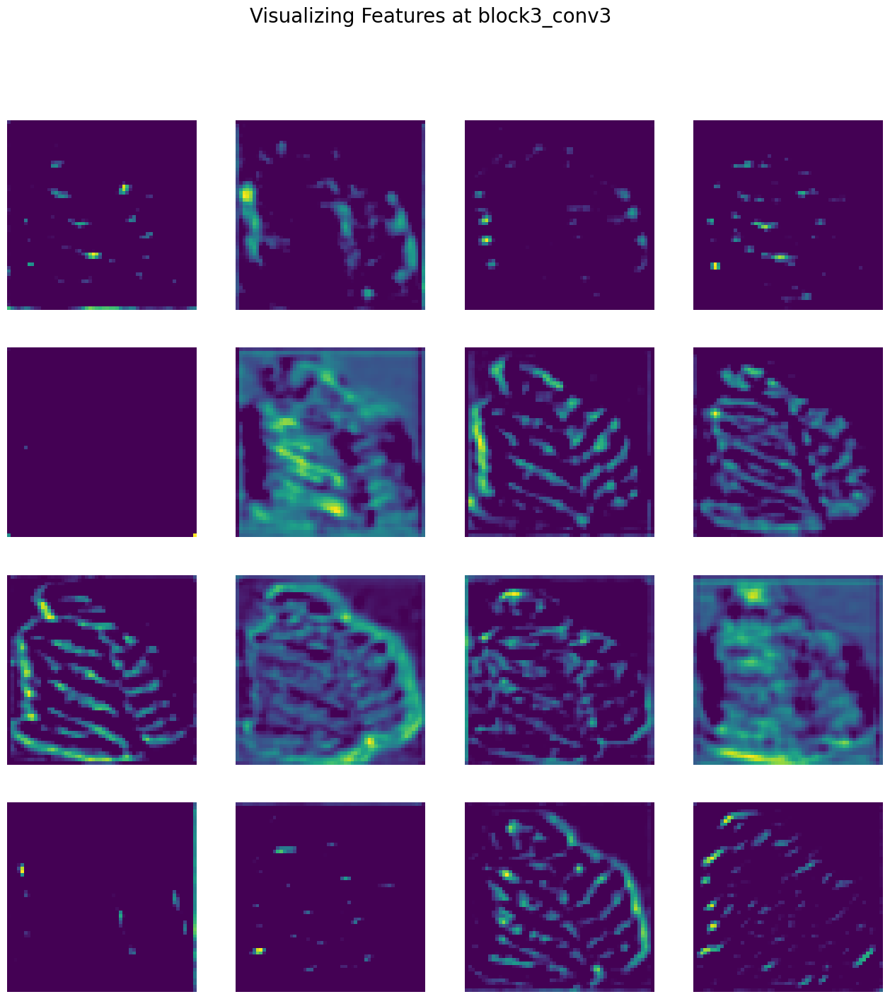

In [ ]:
from tensorflow.keras.models import Model

# 1. Choose a layer to visualize (early layers show edges, deep layers show disease)
layer_name = 'block3_conv3'
intermediate_layer_model = Model(inputs=model.layers[0].input,
                                 outputs=model.layers[0].get_layer(layer_name).output)

# 2. Get a sample leaf
img_batch, _ = next(val_gen)
sample_img = np.expand_dims(img_batch[0], axis=0)

# 3. Get the "Features" the model sees
intermediate_output = intermediate_layer_model.predict(sample_img)

# 4. Plot the first 16 filters (the model's "eyes")
plt.figure(figsize=(16, 16))
for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(intermediate_output[0, :, :, i], cmap='viridis')
    plt.axis('off')
plt.suptitle(f"Visualizing Features at {layer_name}", fontsize=20)
plt.show()

In [ ]:
from sklearn.metrics import classification_report

# Stream A: Traditional Ensemble
# This covers HOG, GLCM, GLRM, and SIFT/SURF logic
print("STREAM A: TRADITIONAL ENSEMBLE PERFORMANCE")
print(classification_report(y_test, y_pred_ensemble, target_names=le.classes_))

# Stream B: Deep Learning (VGG16)
# This covers the automated feature extraction
print("STREAM B: VGG16 CNN PERFORMANCE")
print(classification_report(y_true, y_pred_classes, target_names=list(val_gen.class_indices.keys())))

In [ ]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras import layers, models, optimizers

# 1. Load the ResNet50 base with pre-trained ImageNet weights
# 'include_top=False' removes the original 1000-class head
resnet_base = ResNet50(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

# 2. Freeze the base model layers (Transfer Learning)
# This keeps the pre-trained 'vision' locked
resnet_base.trainable = False

# 3. Build the custom classification head
model_resnet = models.Sequential([
    resnet_base,
    layers.GlobalAveragePooling2D(), # ResNet works better with Global Pooling than Flatten
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5), # Anti-overfitting layer
    layers.Dense(38, activation='softmax') # 38 neurons for your 38 classes
])

# 4. Compile the model
model_resnet.compile(
    optimizer=optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# 5. Start Training
history_resnet = model_resnet.fit(
    train_gen,
    validation_data=val_gen,
    epochs=10
)

Epoch 1/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 179s 122ms/step - accuracy: 0.1635 - loss: 3.1590 - val_accuracy: 0.2700 - val_loss: 2.8984
Epoch 2/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 159s 117ms/step - accuracy: 0.2320 - loss: 2.8493 - val_accuracy: 0.2909 - val_loss: 2.6043
Epoch 3/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 159s 117ms/step - accuracy: 0.2672 - loss: 2.6833 - val_accuracy: 0.3309 - val_loss: 2.4241
Epoch 4/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 159s 117ms/step - accuracy: 0.2818 - loss: 2.6004 - val_accuracy: 0.3382 - val_loss: 2.3397
Epoch 5/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 159s 117ms/step - accuracy: 0.2900 - loss: 2.5465 - val_accuracy: 0.3458 - val_loss: 2.2833
Epoch 6/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 159s 117ms/step - accuracy: 0.3000 - loss: 2.5102 - val_accuracy: 0.3689 - val_loss: 2.2156
Epoch 7/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 170s 125ms/step - accuracy: 0.3060 - loss: 2.4738 - val_accuracy: 0.3838 - val_loss: 2.1929
Epoch 8/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 169s 125ms/step - ac

In [ ]:
import gc
from tensorflow.keras import backend as K

# Clear memory from previous models
K.clear_session()
gc.collect()

0

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras import layers
from tensorflow.keras.applications import MobileNetV2

# 1. Load MobileNetV2
base_model_mobile = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base_model_mobile.trainable = False

# 2. Build the Head
model_mobile = Sequential([
    base_model_mobile,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(38, activation='softmax')
])

model_mobile.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Check if it's ready
model_mobile.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 38)             │         4,902 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,426,854 (9.26 MB)

 Trainable params: 168,870 (659.65 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

training

In [ ]:
history_mobile = model_mobile.fit(
    train_gen,
    validation_data=val_gen,
    epochs=5 # Start with 5 to see the initial accuracy
)

Epoch 1/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 124s 77ms/step - accuracy: 0.8354 - loss: 0.5641 - val_accuracy: 0.9313 - val_loss: 0.2122
Epoch 2/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 85s 63ms/step - accuracy: 0.9172 - loss: 0.2566 - val_accuracy: 0.9413 - val_loss: 0.1759
Epoch 3/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 92s 67ms/step - accuracy: 0.9334 - loss: 0.1996 - val_accuracy: 0.9462 - val_loss: 0.1544
Epoch 4/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 84s 62ms/step - accuracy: 0.9414 - loss: 0.1737 - val_accuracy: 0.9441 - val_loss: 0.1669
Epoch 5/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 90s 66ms/step - accuracy: 0.9470 - loss: 0.1556 - val_accuracy: 0.9524 - val_loss: 0.1344


In [ ]:
model_mobile.save('plant_disease_mobilenet_95.h5')
print("Model saved successfully!")

Model saved successfully!


In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)

# Then in your .fit():
# callbacks=[early_stop]

In [ ]:
import json

# Get class names from the generator
class_indices = train_gen.class_indices
# Reverse it to get {0: 'Apple_Scab', 1: 'Apple_Black_Rot', ...}
labels = {v: k for k, v in class_indices.items()}

with open('class_indices.json', 'w') as f:
    json.dump(labels, f)
print("Class labels saved!")

Class labels saved!


In [ ]:
import cv2
import numpy as np

def preprocess_for_garden(frame):
    """
    Cleans the live camera frame to handle sunlight and noise
    """
    # A. Noise Removal (Gaussian Blur)
    # Reduces graininess from the webcam
    blurred = cv2.GaussianBlur(frame, (5, 5), 0)

    # B. Sunlight Balancing (Histogram Equalization)
    # We do this on the 'Y' (Brightness) channel so colors don't get weird
    img_yuv = cv2.cvtColor(blurred, cv2.COLOR_BGR2YUV)
    img_yuv[:,:,0] = cv2.equalizeHist(img_yuv[:,:,0])
    balanced_frame = cv2.cvtColor(img_yuv, cv2.COLOR_YUV2BGR)

    # C. Prepare for MobileNetV2
    # Resize to 224x224 and scale pixels to [0, 1]
    resized = cv2.resize(balanced_frame, (224, 224))
    final_img = resized / 255.0
    final_img = np.expand_dims(final_img, axis=0) # Add batch dimension

    return final_img

## Complete CropShield Production Pipeline

In [ ]:
import json
import numpy as np
import tensorflow as tf
from PIL import Image

EXPORT_DIR = "/content/cropshield_export"

leaf_validator_model = tf.keras.models.load_model(
    f"{EXPORT_DIR}/cropshield_leaf_validator.keras"
)

disease_model = tf.keras.models.load_model(
    f"{EXPORT_DIR}/cropshield_mobilenetv2_finetuned.keras"
)

with open(
    f"{EXPORT_DIR}/class_indices.json",
    "r"
) as file:
    class_mapping = json.load(file)

class_names = [
    class_mapping[str(index)]
    for index in range(len(class_mapping))
]

print("Leaf validator input:", leaf_validator_model.input_shape)
print("Disease model input:", disease_model.input_shape)
print("Disease classes:", len(class_names))

Leaf validator input: (None, 128, 128, 3)
Disease model input: (None, 224, 224, 3)
Disease classes: 38


In [ ]:
LEAF_THRESHOLD = 0.80
UNCERTAIN_LEAF_THRESHOLD = 0.30

def prepare_leaf_validator_input(image):
    image = image.convert("RGB")
    image = image.resize(
        (128, 128),
        Image.Resampling.BILINEAR
    )

    image_array = np.asarray(
        image,
        dtype=np.float32
    )

    return np.expand_dims(
        image_array,
        axis=0
    )


def prepare_disease_input(image):
    image = image.convert("RGB")
    image = image.resize(
        (224, 224),
        Image.Resampling.BILINEAR
    )

    image_array = np.asarray(
        image,
        dtype=np.float32
    )

    return np.expand_dims(
        image_array,
        axis=0
    )

In [ ]:
def calculate_normalized_entropy(probabilities):
    probabilities = np.clip(
        probabilities,
        1e-10,
        1.0
    )

    entropy = -np.sum(
        probabilities * np.log(probabilities)
    )

    return float(
        entropy / np.log(len(probabilities))
    )

In [ ]:
def run_cropshield_pipeline(image):
    # Stage 1: Leaf suitability
    leaf_input = prepare_leaf_validator_input(image)

    leaf_probability = float(
        leaf_validator_model.predict(
            leaf_input,
            verbose=0
        )[0][0]
    )

    if leaf_probability < UNCERTAIN_LEAF_THRESHOLD:
        return {
            "status": "not_leaf",
            "leaf_probability": leaf_probability,
            "message": (
                "No suitable plant leaf was detected. "
                "Upload a clear leaf image."
            )
        }

    if leaf_probability < LEAF_THRESHOLD:
        return {
            "status": "uncertain_leaf",
            "leaf_probability": leaf_probability,
            "message": (
                "The image may contain a leaf, but it is unclear. "
                "Capture a sharper and closer photo."
            )
        }

    # Stage 2: Disease prediction
    disease_input = prepare_disease_input(image)

    probabilities = disease_model.predict(
        disease_input,
        verbose=0
    )[0]

    sorted_indices = np.argsort(
        probabilities
    )[::-1]

    top_1_index = int(sorted_indices[0])
    top_2_index = int(sorted_indices[1])
    top_3_indices = sorted_indices[:3]

    confidence = float(
        probabilities[top_1_index]
    )

    second_confidence = float(
        probabilities[top_2_index]
    )

    margin = confidence - second_confidence

    entropy = calculate_normalized_entropy(
        probabilities
    )

    top_3 = [
        {
            "class_name": class_names[int(index)],
            "confidence": float(probabilities[index])
        }
        for index in top_3_indices
    ]

    # Initial uncertainty rules
    if (
        confidence < 0.65
        or margin < 0.15
        or entropy > 0.45
    ):
        diagnosis_status = "uncertain_diagnosis"
        message = (
            "A leaf was detected, but the disease diagnosis "
            "is uncertain. Retake the photo or consult an expert."
        )
    else:
        diagnosis_status = "confident_diagnosis"
        message = "A sufficiently confident diagnosis was produced."

    return {
        "status": diagnosis_status,
        "leaf_probability": leaf_probability,
        "predicted_class": class_names[top_1_index],
        "confidence": confidence,
        "confidence_margin": margin,
        "entropy": entropy,
        "top_3": top_3,
        "message": message
    }

In [ ]:
from google.colab import files

pipeline_uploads = files.upload()

Saving WhatsApp Image 2026-08-02 at 3.50.03 PM (1).jpeg to WhatsApp Image 2026-08-02 at 3.50.03 PM (1) (2).jpeg
Saving WhatsApp Image 2026-08-02 at 3.50.03 PM.jpeg to WhatsApp Image 2026-08-02 at 3.50.03 PM (4).jpeg
Saving WhatsApp Image 2026-08-02 at 3.50.02 PM.jpeg to WhatsApp Image 2026-08-02 at 3.50.02 PM (2).jpeg
Saving WhatsApp Image 2026-08-02 at 3.50.01 PM (2).jpeg to WhatsApp Image 2026-08-02 at 3.50.01 PM (2) (2).jpeg
Saving WhatsApp Image 2026-08-02 at 3.50.01 PM (1).jpeg to WhatsApp Image 2026-08-02 at 3.50.01 PM (1) (2).jpeg
Saving WhatsApp Image 2026-08-02 at 3.50.01 PM.jpeg to WhatsApp Image 2026-08-02 at 3.50.01 PM (4).jpeg
Saving WhatsApp Image 2026-08-02 at 3.50.00 PM.jpeg to WhatsApp Image 2026-08-02 at 3.50.00 PM (2).jpeg


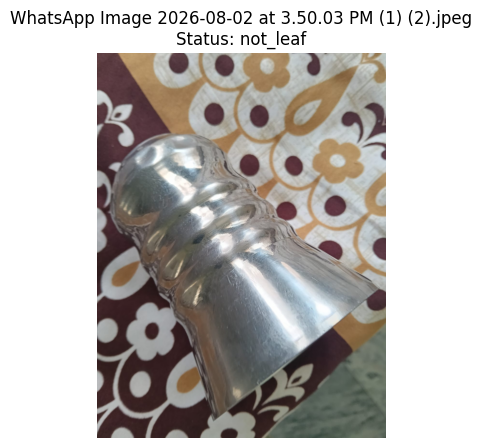

{
    "status": "not_leaf",
    "leaf_probability": 2.3663757531267038e-07,
    "message": "No suitable plant leaf was detected. Upload a clear leaf image."
}
--------------------------------------------------------------------------------


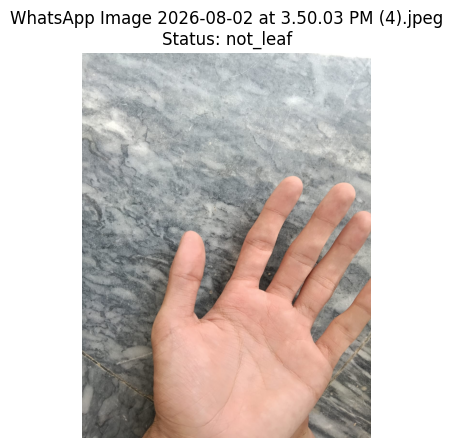

{
    "status": "not_leaf",
    "leaf_probability": 0.2231741100549698,
    "message": "No suitable plant leaf was detected. Upload a clear leaf image."
}
--------------------------------------------------------------------------------


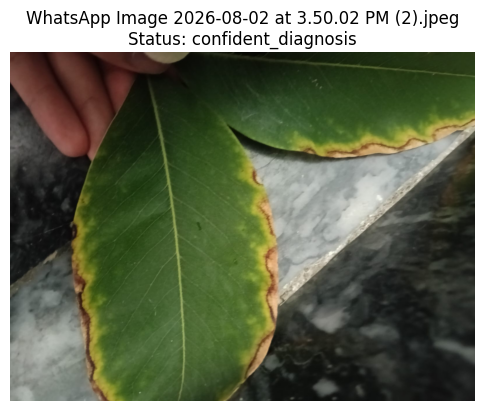

{
    "status": "confident_diagnosis",
    "leaf_probability": 0.9952025413513184,
    "predicted_class": "Pepper,_bell___Bacterial_spot",
    "confidence": 0.890941858291626,
    "confidence_margin": 0.8330860249698162,
    "entropy": 0.12687249041479493,
    "top_3": [
        {
            "class_name": "Pepper,_bell___Bacterial_spot",
            "confidence": 0.890941858291626
        },
        {
            "class_name": "Blueberry___healthy",
            "confidence": 0.05785583332180977
        },
        {
            "class_name": "Cherry_(including_sour)___Powdery_mildew",
            "confidence": 0.040528904646635056
        }
    ],
    "message": "A sufficiently confident diagnosis was produced."
}
--------------------------------------------------------------------------------


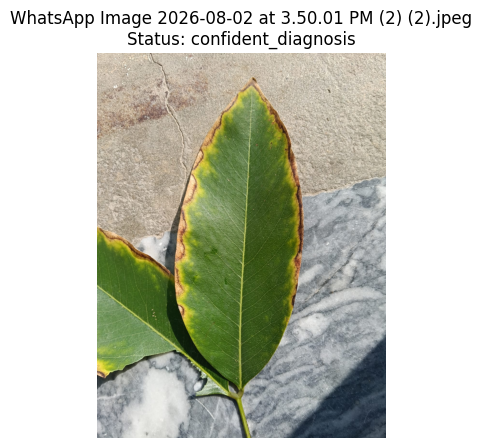

{
    "status": "confident_diagnosis",
    "leaf_probability": 0.9999991655349731,
    "predicted_class": "Pepper,_bell___Bacterial_spot",
    "confidence": 0.9996525049209595,
    "confidence_margin": 0.9993749595305417,
    "entropy": 0.0009253773160532562,
    "top_3": [
        {
            "class_name": "Pepper,_bell___Bacterial_spot",
            "confidence": 0.9996525049209595
        },
        {
            "class_name": "Orange___Haunglongbing_(Citrus_greening)",
            "confidence": 0.00027754539041779935
        },
        {
            "class_name": "Tomato___Early_blight",
            "confidence": 3.7018689909018576e-05
        }
    ],
    "message": "A sufficiently confident diagnosis was produced."
}
--------------------------------------------------------------------------------


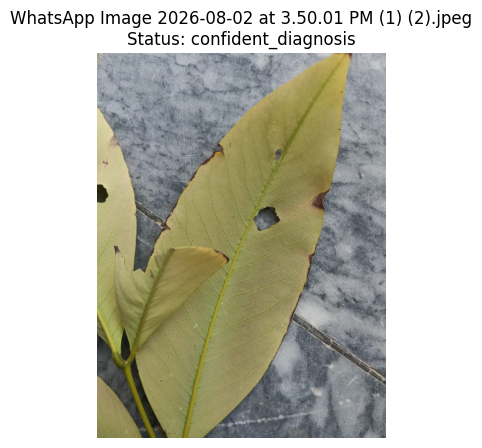

{
    "status": "confident_diagnosis",
    "leaf_probability": 0.9997270703315735,
    "predicted_class": "Peach___Bacterial_spot",
    "confidence": 0.9982033967971802,
    "confidence_margin": 0.9966385272564366,
    "entropy": 0.0038213330128005086,
    "top_3": [
        {
            "class_name": "Peach___Bacterial_spot",
            "confidence": 0.9982033967971802
        },
        {
            "class_name": "Pepper,_bell___Bacterial_spot",
            "confidence": 0.0015648695407435298
        },
        {
            "class_name": "Soybean___healthy",
            "confidence": 0.00022177028586156666
        }
    ],
    "message": "A sufficiently confident diagnosis was produced."
}
--------------------------------------------------------------------------------


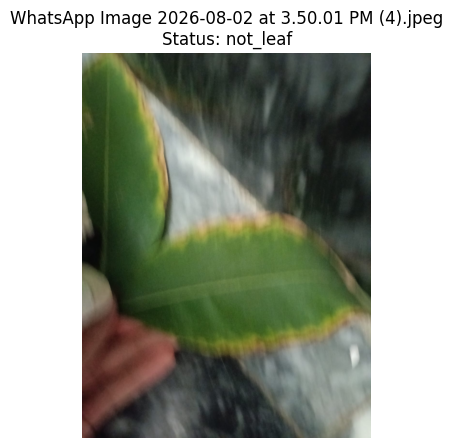

{
    "status": "not_leaf",
    "leaf_probability": 0.012369324453175068,
    "message": "No suitable plant leaf was detected. Upload a clear leaf image."
}
--------------------------------------------------------------------------------


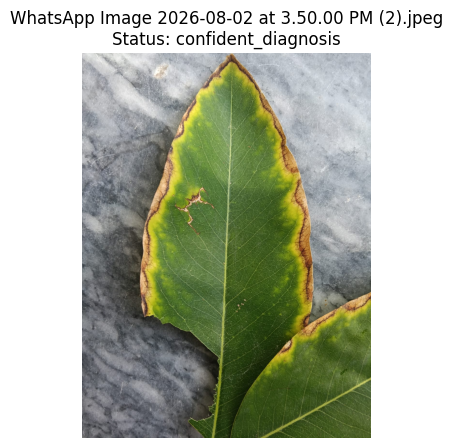

{
    "status": "confident_diagnosis",
    "leaf_probability": 0.9999997615814209,
    "predicted_class": "Peach___Bacterial_spot",
    "confidence": 0.7686665058135986,
    "confidence_margin": 0.633295327425003,
    "entropy": 0.19569531533220347,
    "top_3": [
        {
            "class_name": "Peach___Bacterial_spot",
            "confidence": 0.7686665058135986
        },
        {
            "class_name": "Pepper,_bell___Bacterial_spot",
            "confidence": 0.13537117838859558
        },
        {
            "class_name": "Tomato___Bacterial_spot",
            "confidence": 0.09357985109090805
        }
    ],
    "message": "A sufficiently confident diagnosis was produced."
}
--------------------------------------------------------------------------------


In [ ]:
import io
import matplotlib.pyplot as plt

for file_name, file_data in pipeline_uploads.items():
    image = Image.open(
        io.BytesIO(file_data)
    ).convert("RGB")

    result = run_cropshield_pipeline(image)

    plt.figure(figsize=(6, 5))
    plt.imshow(image)
    plt.axis("off")
    plt.title(
        f"{file_name}\n"
        f"Status: {result['status']}"
    )
    plt.show()

    print(json.dumps(result, indent=4))
    print("-" * 80)

In [ ]:
import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "/content/CropShield_Updated_Final_Artifacts",
    "zip",
    "/content/cropshield_export"
)

print("ZIP created:", zip_path)
files.download(zip_path)

ZIP created: /content/CropShield_Updated_Final_Artifacts.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os

print(os.listdir("/content/cropshield_export"))

['train_split.csv', 'leaf_validator_metadata.json', 'confused_class_pairs.csv', 'classification_report.csv', 'class_indices.json', 'test_split.csv', 'cropshield_leaf_validator.keras', 'model_metrics.json', 'validation_split.csv', 'cropshield_mobilenetv2_finetuned.keras', 'baseline_vs_finetuned.csv']
